## **Severe Maternal Morbidity (SMM) / "Near-Miss" Models -- Modelo B**

Predictive models for **severe maternal morbidity ("near-miss")** among the obstetric cohort identified in
MIMIC-IV, built as the **second predictive model** of the doctoral thesis (Universidad del Norte,
Barranquilla), complementary to `maternal_mortality_models.ipynb` (Modelo A, in-hospital maternal death).

This notebook mirrors, step by step, the methodology validated in `maternal_mortality_models.ipynb` and,
before it, `newborn_models_v5.ipynb` (cleaning, IQRx3 outlier winsorization, imputation, categorical encoding,
correlation analysis, scaling, train/test split, 5 models -- Random Forest, XGBoost, Extra Trees, Logistic
Regression, Stacking -- evaluation and SHAP), adapting the **outcome definition** and the **class-imbalance
framing** to SMM instead of mortality.

> **This notebook has NOT been run against Emmanuel's real database** (`localhost:5433`, only
> reachable from his machine). All the code should be treated as a **syntactically valid** draft
> (verified with `ast.parse()`), pending end-to-end execution. It depends on Emmanuel first running
> `sql/02_cohort_mortality/maternal_cohort_expanded_en.sql` and `sql/03_cohort_smm/smm_cohort_en.sql`
> against his instance.


### **0.1 Source of the 20 SMM indicators and the relative-frequency finding**

- **Definition and indicators.** The 20 severe maternal morbidity indicators used here (table
  `mimiciv.smm_code_patterns`, see Section 2.2) come from **CDC (2023)**, via the **HRSA Federally
  Available Data (FAD) Resource Document 2023**, reproduced in Appendix 1 of the *"Severe Maternal
  Morbidity Report 2017-2021"* report by Nebraska DHHS (Jul-2024). The original indicator #18 (**blood
  product transfusion**) was **officially retired by HRSA in 2023** ("no longer used"), so this
  notebook -- like the Nebraska report -- works with the **20 currently active indicators**, grouped into
  **7 clinical categories**: `Cardiac`, `Renal`, `Respiratory`, `Hemorrhage`, `Sepsis`, `Other_Obstetric`,
  `Other_Medical`.
- **Relative frequency vs. maternal mortality.** **Callaghan et al. (2012)** found that severe maternal
  morbidity occurs **~100 times more often** than in-hospital maternal death. This is consistent with
  published SMM rates (**~58-88 cases per 10,000 deliveries**, CDC/Nebraska DHHS), versus in-hospital
  maternal mortality rates on the order of fractions of a case per 10,000 -- and explains why Modelo A had
  only 36-45 positive cases out of ~23,000 admissions, while Modelo B should have, in the same cohort,
  **tens to a couple hundred positive cases**.


### **0.2 Modelo A (Maternal mortality) vs. Modelo B (SMM / near-miss)**

| Aspect | **Modelo A** -- Maternal mortality | **Modelo B** -- SMM / near-miss (this notebook) |
|---|---|---|
| Outcome | Death recorded in the index admission or in any later admission | At least 1 of 20 CDC/HRSA severe-maternal-morbidity indicators (`mimiciv.hadm_with_smm`) |
| N positives (25,736 admissions) | **41** (0.159%) | **475** (1.846%); 252 of 8,857 delivery hospitalizations (2.845%) |
| Prevalence | Extreme (<0.2%) | Low-moderate (~1.8%), **not extreme** |
| Positives in the 80/20 test split | 8 | 95 |
| Evaluation stability | With 8 positives in the test set, any minority-class metric is highly unstable (changes >10 pp with 1 case) | With 95 positives in the test set, point-estimate metrics are substantially more stable |
| Recommended methodological tone | **Exploratory / hypothesis-generating** -- requires external validation before any clinical claim | **More robust evidence**, reportable with fewer caveats than Modelo A (still single-center, ICD-based labels, no external validation) |
| Imbalance best practices | `class_weight`, stratified k-fold, PR-AUC -- almost mandatory | Same best practices kept |
| Outcome source | Exploratory SQL reproduced in Section 2.1 of `maternal_mortality_models.ipynb` | CDC (2023) via HRSA FAD 2023, reproduced in the Nebraska DHHS report (Jul-2024); Callaghan et al. (2012) |

**Conclusion of this table:** Modelo B does not replace Modelo A -- it answers a different clinical
question (severe, potentially preventable/near-miss morbidity vs. mortality) and does so on a stronger
statistical footing, given its much larger number of positive cases. Both models should be presented as
complementary in the thesis.

### **1. Load libraries required for running models**

In [98]:
# import
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import warnings
import shap

import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec
from scipy.stats import gaussian_kde

# from
from sklearn.naive_bayes import CategoricalNB, GaussianNB, BernoulliNB
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate,GridSearchCV
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_auc_score,
                            roc_curve, auc, precision_score, recall_score, average_precision_score,
                            brier_score_loss, precision_recall_curve, PrecisionRecallDisplay, f1_score,
                            silhouette_score, balanced_accuracy_score)
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.isotonic import IsotonicRegression
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from contextlib import redirect_stdout
from mpl_toolkits.mplot3d import Axes3D
from lightgbm import LGBMClassifier

# Output folders (relative to notebooks/): tables -> data/, figures -> figures/
DATA_DIR = os.path.join('..', 'data')
FIG_DIR = os.path.join('..', 'figures')
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

In [99]:
# Add own Libraries
# Add root directory to path
sys.path.append(os.path.abspath(".."))

import importlib
import libraries.database as db_lib
import libraries.functions as functions_lib

importlib.reload(db_lib)
importlib.reload(functions_lib)
engine = db_lib.get_connect_database()

### **2. Cohort Construction: SMM Outcome over Two Denominators**

#### **2.1 The near-miss / SMM concept and the 7 clinical categories**

An admission qualifies as **SMM-positive** (`outcome_smm = 1`) if it carries at least one ICD-10-CM
diagnosis or ICD-10-PCS procedure matching any of the **20 CDC/HRSA FAD-2023 indicators** (view
`mimiciv.hadm_with_smm`, built in `sql/03_cohort_smm/smm_cohort_en.sql`). The 20 indicators are
grouped into **7 clinical categories**:

| Clinical category | # CDC indicators included |
|---|---|
| **Cardiac** | 6 (AMI, aneurysm, cardiac arrest/V-fib, conversion of cardiac rhythm, heart failure/arrest during surgery, pulmonary edema/acute heart failure) |
| **Renal** | 1 (acute renal failure) |
| **Respiratory** | 3 (ARDS, temporary tracheostomy, ventilation) |
| **Hemorrhage** | 3 (DIC, shock, hysterectomy) |
| **Sepsis** | 1 (sepsis) |
| **Other_Obstetric** | 4 (amniotic fluid embolism, eclampsia, severe anesthesia complications, air/thrombotic embolism) |
| **Other_Medical** | 2 (puerperal cerebrovascular disorders, sickle cell disease with crisis) |
| **Total** | **20** (indicator #18, blood-product transfusion, excluded -- retired by HRSA in 2023) |

> **Important note on using these categories as *features*.** The 7 categories (and their per-admission
> indicator counts) are derived **directly from the outcome itself**: an admission only has
> `cardiac_count > 0`, etc., if it already met the SMM definition. Using them as predictors of the
> binary `outcome_smm` model would be **information leakage** -- they are, in practice,
> components of the target, not independent covariates. That's why this notebook uses them **only**
> for (a) descriptive/epidemiological analysis (this section and 2.6-2.7) and (b) as a possible **target
> for a secondary multiclass model** conditioned on `outcome_smm = 1` (Section 15) -- never as input to
> the main binary model (Section 10 explicitly excludes them from `X`).


#### **2.2 SQL -- SMM indicator catalogue and outcome views (`smm_cohort_en.sql`)**

```sql
-- ============================================================================
-- "NEAR-MISS" / SEVERE MATERNAL MORBIDITY (SMM) COHORT -- Modelo B
-- ============================================================================
-- Source of the 20 indicators and ICD-10-CM/PCS codes: CDC (2023), via the
-- HRSA Federally Available Data (FAD) Resource Document 2023, reproduced in
-- Appendix 1 of the Nebraska DHHS "Severe Maternal Morbidity Report
-- 2017-2021" (Jul-2024). Blood-product transfusion (#18) is excluded because
-- HRSA officially retired it in 2023.
--
-- IMPORTANT: the CDC's official SMM definition is measured over "delivery
-- hospitalizations", not over any admission with an obstetric diagnosis --
-- hence the TWO denominators computed in Step 4 (see Section 2.4 of this
-- notebook).
-- ============================================================================

-- Step 1: catalogue of ICD-10 patterns for the 20 currently-active SMM indicators
CREATE TABLE mimiciv.smm_code_patterns (
    indicator_group  VARCHAR(60),
    indicator_name   VARCHAR(60),
    code_type        VARCHAR(2),   -- 'DX' (diagnoses_icd) or 'PR' (procedures_icd)
    code_pattern     VARCHAR(10)   -- prefix; compared as icd_code LIKE pattern || '%'
);
-- ... 20 indicators / ~60 code patterns (full INSERT in the actual script --
-- see sql/03_cohort_smm/smm_cohort_en.sql, lines 40-162)

-- Step 2: hadm_id with at least one SMM indicator (ICD-10 only; MIMIC-IV has
-- no ICD-9-coded data after Oct-2015)
CREATE VIEW mimiciv.hadm_with_smm AS
SELECT DISTINCT d.subject_id, d.hadm_id, p.indicator_group, p.indicator_name
FROM mimiciv.diagnoses_icd d
JOIN mimiciv.smm_code_patterns p
  ON p.code_type = 'DX'
 AND d.icd_version = 10
 AND d.icd_code LIKE p.code_pattern || '%'
UNION
SELECT DISTINCT pr.subject_id, pr.hadm_id, p.indicator_group, p.indicator_name
FROM mimiciv.procedures_icd pr
JOIN mimiciv.smm_code_patterns p
  ON p.code_type = 'PR'
 AND pr.icd_version = 10
 AND pr.icd_code LIKE p.code_pattern || '%';

-- Step 3: delivery hospitalizations (proxy: delivery-outcome code Z37.x, or
-- delivery encounter O80.x/O82.x) -- the CDC's OFFICIAL denominator
CREATE VIEW mimiciv.hadm_delivery_hospitalization AS
SELECT DISTINCT d.subject_id, d.hadm_id
FROM mimiciv.diagnoses_icd d
WHERE d.icd_version = 10
  AND (d.icd_code LIKE 'Z37%' OR d.icd_code LIKE 'O80%' OR d.icd_code LIKE 'O82%');
```


#### **2.3 SQL -- Expanded obstetric cohort (`maternal_cohort_expanded_en.sql`)**

```sql
-- ============================================================================
-- EXPANDED MATERNAL COHORT -- complementary denominator (more absolute cases)
-- ============================================================================
-- Step 1: expanded universe of obstetric diagnoses (text match + ICD range)
CREATE VIEW mimiciv.pregnancy_diagnoses_expanded AS
SELECT DISTINCT icd_code, icd_version, long_title
FROM mimiciv.d_icd_diagnoses
WHERE
    long_title ILIKE '%PREGNAN%' OR long_title ILIKE '%OBSTETRIC%'
    OR long_title ILIKE '%FETAL%'  OR long_title ILIKE '%DELIVERY%'
    OR long_title ILIKE '%PUERPERIUM%' OR long_title ILIKE '%POSTPARTUM%'
    OR long_title ILIKE '%GESTATION%'
    OR (icd_version = 9  AND icd_code ~ '^[0-9]' AND LEFT(icd_code,3)::int BETWEEN 630 AND 679)
    OR (icd_version = 9  AND LEFT(icd_code,3) IN ('V22','V23','V24','V27','V28'))
    OR (icd_version = 10 AND LEFT(icd_code,1) = 'O')
    OR (icd_version = 10 AND (icd_code LIKE 'Z33%' OR icd_code LIKE 'Z34%'
                               OR icd_code LIKE 'Z37%' OR icd_code LIKE 'Z39%'));

-- Step 2: expanded cohort -- WITHOUT requiring an ICU stay, WITHOUT a date
-- restriction (unlike Modelo A's original cohort). Age computed with
-- ANCHOR_AGE/ANCHOR_YEAR (NOT dob -- see the methodological note in the
-- original script on why dob is not reliable for adult patients).
WITH maternal_admissions AS (
    SELECT DISTINCT
        a.subject_id, a.hadm_id,
        p.anchor_age + (DATE_PART('year', a.admittime) - p.anchor_year) AS approx_age
    FROM mimiciv.admissions a
    JOIN mimiciv.patients p ON a.subject_id = p.subject_id
    WHERE p.gender = 'F'
      AND p.anchor_age + (DATE_PART('year', a.admittime) - p.anchor_year) BETWEEN 12 AND 55
      AND (a.subject_id, a.hadm_id) IN (
            SELECT d.subject_id, d.hadm_id
            FROM mimiciv.diagnoses_icd d
            JOIN mimiciv.pregnancy_diagnoses_expanded de
              ON d.icd_code = de.icd_code AND d.icd_version = de.icd_version
      )
)
SELECT COUNT(*)                  AS n_admissions,
       COUNT(DISTINCT subject_id) AS n_patients
FROM maternal_admissions;
-- (later joined with icustays -> had_icu_stay, and with hadm_with_smm /
--  hadm_delivery_hospitalization to produce mimiciv.cohort_smm_dataset --
--  see Section 2.8)
```


#### **2.4 Exploratory comparison of both denominators -- BEFORE deciding**

Before settling on which cohort feeds the final model, we compare:

- **(a) Official CDC-comparable denominator:** only **delivery** hospitalizations
  (`mimiciv.hadm_delivery_hospitalization`) -- comparable 1:1 with published rates (58-88 SMM per 10,000
  deliveries).
- **(b) Complementary denominator (expanded obstetric cohort):** every obstetric admission from
  `maternal_cohort_expanded_en.sql` -- a wider denominator, more absolute cases, but no longer 1:1
  comparable with the published rate (it includes prenatal follow-ups, pregnancy-supervision codes, etc.
  that are not "deliveries").

The next cell runs the aggregate `SELECT` from `smm_cohort_en.sql` (Step 4) to get both
counts at once.


 total_obstetric_admissions  total_delivery_hospitalizations  total_with_smm_any_admission  total_with_smm_at_delivery
                      25736                             8857                           475                         252

SMM rate (expanded cohort, N=25736):  184.6 per 10,000 admissions
SMM rate (deliveries only,  N=8857): 284.5 per 10,000 deliveries
Published reference range (CDC / Nebraska DHHS): 58-88 per 10,000 deliveries


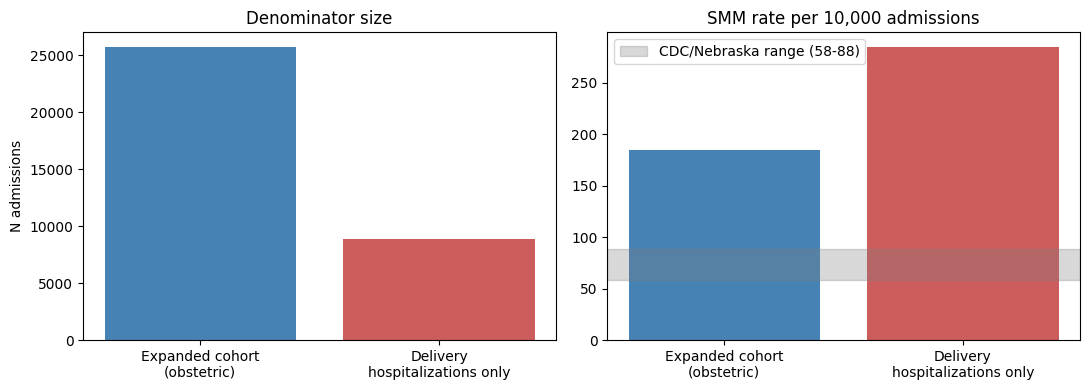

In [100]:
query_denom = db_lib.get_smm_denominator_comparison_query()
df_denom = pd.read_sql(query_denom, engine)
print(df_denom.to_string(index=False))

total_obst   = df_denom.loc[0, "total_obstetric_admissions"]
total_parto  = df_denom.loc[0, "total_delivery_hospitalizations"]
smm_obst     = df_denom.loc[0, "total_with_smm_any_admission"]
smm_parto    = df_denom.loc[0, "total_with_smm_at_delivery"]

rate_obst_10k  = (smm_obst  / total_obst)  * 10000 if total_obst  else np.nan
rate_parto_10k = (smm_parto / total_parto) * 10000 if total_parto else np.nan

print(f"\nSMM rate (expanded cohort, N={total_obst}):  {rate_obst_10k:.1f} per 10,000 admissions")
print(f"SMM rate (deliveries only,  N={total_parto}): {rate_parto_10k:.1f} per 10,000 deliveries")
print("Published reference range (CDC / Nebraska DHHS): 58-88 per 10,000 deliveries")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(["Expanded cohort\n(obstetric)", "Delivery\nhospitalizations only"],
            [total_obst, total_parto], color=["steelblue", "indianred"])
axes[0].set_title("Denominator size")
axes[0].set_ylabel("N admissions")

axes[1].bar(["Expanded cohort\n(obstetric)", "Delivery\nhospitalizations only"],
            [rate_obst_10k, rate_parto_10k], color=["steelblue", "indianred"])
axes[1].axhspan(58, 88, color="gray", alpha=0.3, label="CDC/Nebraska range (58-88)")
axes[1].set_title("SMM rate per 10,000 admissions")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Fig_SMM_Denominator_Comparison.pdf"), format="pdf", bbox_inches="tight")
plt.savefig(os.path.join(FIG_DIR, "Fig_SMM_Denominator_Comparison.png"), format="png", dpi=300, bbox_inches="tight")
plt.show()

#### **2.5 Decision: which cohort feeds the final model**

**Decision adopted in this notebook** (to be validated by Emmanuel, see Section 17):

- The **main model** (Sections 3-14) is trained on the **full expanded obstetric cohort**
  (denominator (b)), not on deliveries only -- because (i) it contributes the largest absolute number of
  SMM-positive cases, improving the model's statistical power, and (ii) the `is_delivery_hospitalization`
  flag is included as an **informative variable** inside `X` (not as a mandatory filter), so the model
  can learn whether the delivery context modulates risk, without discarding SMM cases detected in
  non-delivery obstetric admissions (e.g. prenatal or puerperal complications treated in separate
  admissions).
- As a **sensitivity/comparability-with-the-literature check**, Section 12.6 recomputes the best model's
  metrics restricting the test set to `is_delivery_hospitalization == 1`
  (denominator (a), official CDC) and compares the observed rate with the published range (58-88/10,000).
- This keeps **both paths represented**: the size comparison (2.4), the main model on the
  expanded cohort, and the sensitivity check on the delivery subset.


#### **2.6 The 7 clinical categories -- descriptive analysis**

indicator_group  n_hospitalizations
          Renal                 180
     Hemorrhage                 131
    Respiratory                  89
  Other_Medical                  77
         Sepsis                  62
        Cardiac                  61
Other_Obstetric                  56


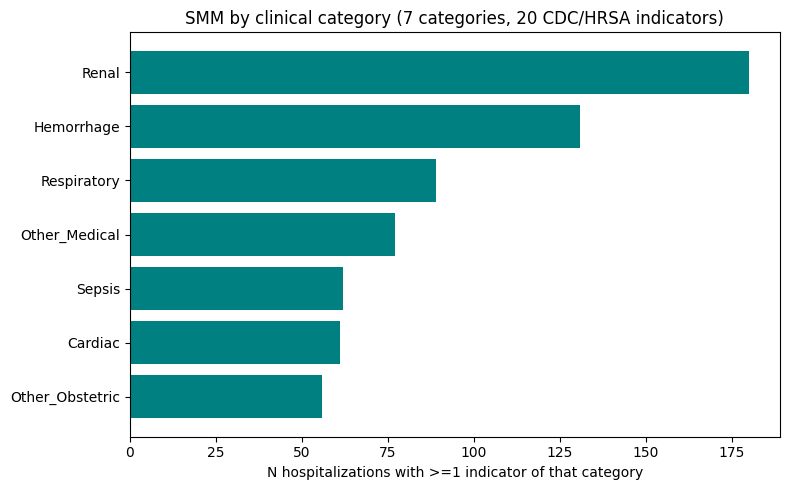

In [101]:
query_cat = db_lib.get_smm_category_summary_query()
df_cat_summary = pd.read_sql(query_cat, engine)
print(df_cat_summary.to_string(index=False))

plt.figure(figsize=(8, 5))
plt.barh(df_cat_summary["indicator_group"], df_cat_summary["n_hospitalizations"], color="teal")
plt.xlabel("N hospitalizations with >=1 indicator of that category")
plt.title("SMM by clinical category (7 categories, 20 CDC/HRSA indicators)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Fig_SMM_Category_Counts.pdf"), format="pdf", bbox_inches="tight")
plt.savefig(os.path.join(FIG_DIR, "Fig_SMM_Category_Counts.png"), format="png", dpi=300, bbox_inches="tight")
plt.show()

In [102]:
query_ind = db_lib.get_smm_indicator_summary_query()
df_indicator_summary = pd.read_sql(query_ind, engine)
print(f"Total distinct indicators with >=1 case: {df_indicator_summary['indicator_name'].nunique()} / 20")
df_indicator_summary

Total distinct indicators with >=1 case: 20 / 20


,indicator_group,indicator_name,n_hospitalizations
0,Cardiac,Pulmonary edema/acute heart failure,45
1,Cardiac,Conversion of cardiac rhythm,8
2,Cardiac,Acute myocardial infarction,7
3,Cardiac,Cardiac arrest/ventricular fibrillation,7
4,Cardiac,Aneurysm,5
5,Cardiac,Heart failure/arrest during surgery or procedure,1
6,Hemorrhage,Shock,72
7,Hemorrhage,DIC,61
8,Hemorrhage,Hysterectomy,41
9,Other_Medical,Puerperal cerebrovascular disorders,55


#### **2.7 Counts by category and multiclass label -- informative features, NOT predictors**

`mimiciv.cohort_smm_dataset` (Section 2.8) will include, in addition to the binary outcome `outcome_smm`:

- 7 count columns (`cardiac_count`, `renal_count`, `respiratory_count`, `hemorrhage_count`,
  `sepsis_count`, `other_obstetric_count`, `other_medical_count`) -- number of distinct indicators of that
  category found in the admission.
- `primary_smm_category` -- the category with the highest count for that admission (or `'No_SMM'` if
  `outcome_smm = 0`), intended as a **possible multiclass target** for a secondary model (Section 15),
  **not** as an input feature of the main binary model (see the information-leakage warning in
  Section 2.1).


#### **2.8 Dataset Assembly -- `mimiciv.cohort_smm_dataset`**

It is assembled following the **same three-level pattern (`X` -> `Y` -> `K`)** used for
`mimiciv.cohort_maternal_dataset` in `maternal_mortality_models.ipynb` (Section 2.4), with two differences:

1. **Source `Y`:** instead of `mimiciv.cohort_maternal` (the original cohort, with a date filter and a
   mandatory ICU stay), it starts from the **expanded cohort** (`maternal_admissions` from
   `maternal_cohort_expanded_en.sql`: no mandatory ICU, no date filter, age via `anchor_age`), and
   this notebook's outcome/flag columns are added (`outcome_smm`, `is_delivery_hospitalization`,
   per-category counts, `primary_smm_category`).
2. **Level `K` (chart/lab event extraction):** it is **identical, item by item**, to the block in
   `mimiciv.cohort_maternal_dataset` (same 27 `itemid`s, same `MIN(charttime)` +
   `MAX(valuenum)` pattern per admission) -- not repeated here verbatim for brevity; copy that block as-is,
   only changing `Y`'s `FROM` as shown below.

```sql
CREATE TABLE mimiciv.cohort_smm_dataset AS
SELECT K.*
FROM
(
    SELECT Y.subject_id, Y.hadm_id, Y.stay_id, Y.dob, Y.age_at_admission
           , Y.ethnicity, Y.insurance, Y.language, Y.admission_type, Y.admission_location
           , Y.icu_stay, Y.icu_stay_count
           , Y.outcome_smm, Y.is_delivery_hospitalization
           , Y.cardiac_count, Y.renal_count, Y.respiratory_count, Y.hemorrhage_count
           , Y.sepsis_count, Y.other_obstetric_count, Y.other_medical_count
           , Y.primary_smm_category
           -- Y.gdg_m01 .. Y.gdg_m30 (reuses the same diagnostic-group scaffolding
           --  described in database.py / Modelo A's Section 2.2)
    FROM
    (
        SELECT am.subject_id, am.hadm_id
               , (SELECT MIN(i.stay_id) FROM mimiciv.icustays i
                   WHERE i.subject_id = am.subject_id AND i.hadm_id = am.hadm_id) AS stay_id
               , p.dob
               , am.approx_age AS age_at_admission
               , a.ethnicity, a.insurance, a.language, a.admission_type, a.admission_location
               , (EXISTS (SELECT 1 FROM mimiciv.icustays i
                           WHERE i.subject_id = am.subject_id AND i.hadm_id = am.hadm_id))::int AS icu_stay
               , (SELECT COUNT(1) FROM mimiciv.icustays i
                   WHERE i.subject_id = am.subject_id AND i.hadm_id = am.hadm_id) AS icu_stay_count
               , (CASE WHEN smm.hadm_id IS NOT NULL THEN 1 ELSE 0 END)          AS outcome_smm
               , (CASE WHEN dh.hadm_id  IS NOT NULL THEN 1 ELSE 0 END)          AS is_delivery_hospitalization
               , COALESCE(cat.cardiac_count, 0)          AS cardiac_count
               , COALESCE(cat.renal_count, 0)            AS renal_count
               , COALESCE(cat.respiratory_count, 0)      AS respiratory_count
               , COALESCE(cat.hemorrhage_count, 0)       AS hemorrhage_count
               , COALESCE(cat.sepsis_count, 0)            AS sepsis_count
               , COALESCE(cat.other_obstetric_count, 0)  AS other_obstetric_count
               , COALESCE(cat.other_medical_count, 0)    AS other_medical_count
               , CASE WHEN smm.hadm_id IS NULL THEN 'No_SMM'
                      ELSE cat.primary_category END       AS primary_smm_category
        FROM (
                -- maternal_admissions from maternal_cohort_expanded_en.sql (Step 2, Section 2.3)
                SELECT DISTINCT a.subject_id, a.hadm_id,
                       p.anchor_age + (DATE_PART('year', a.admittime) - p.anchor_year) AS approx_age
                FROM mimiciv.admissions a
                JOIN mimiciv.patients p ON a.subject_id = p.subject_id
                WHERE p.gender = 'F'
                  AND p.anchor_age + (DATE_PART('year', a.admittime) - p.anchor_year) BETWEEN 12 AND 55
                  AND (a.subject_id, a.hadm_id) IN (
                        SELECT d.subject_id, d.hadm_id FROM mimiciv.diagnoses_icd d
                        JOIN mimiciv.pregnancy_diagnoses_expanded de
                          ON d.icd_code = de.icd_code AND d.icd_version = de.icd_version)
             ) am
        JOIN mimiciv.admissions a ON a.subject_id = am.subject_id AND a.hadm_id = am.hadm_id
        JOIN mimiciv.patients   p ON p.subject_id = am.subject_id
        LEFT JOIN mimiciv.hadm_delivery_hospitalization dh
               ON dh.subject_id = am.subject_id AND dh.hadm_id = am.hadm_id
        LEFT JOIN ( SELECT subject_id, hadm_id, MIN(hadm_id) FILTER (WHERE true) AS hadm_id_chk
                    FROM mimiciv.hadm_with_smm GROUP BY subject_id, hadm_id ) smm
               ON smm.subject_id = am.subject_id AND smm.hadm_id = am.hadm_id
        LEFT JOIN (
                -- pivot of per-category counts + dominant category, from hadm_with_smm
                SELECT subject_id, hadm_id
                       , COUNT(DISTINCT indicator_name) FILTER (WHERE indicator_group = 'Cardiac')          AS cardiac_count
                       , COUNT(DISTINCT indicator_name) FILTER (WHERE indicator_group = 'Renal')            AS renal_count
                       , COUNT(DISTINCT indicator_name) FILTER (WHERE indicator_group = 'Respiratory')      AS respiratory_count
                       , COUNT(DISTINCT indicator_name) FILTER (WHERE indicator_group = 'Hemorrhage')       AS hemorrhage_count
                       , COUNT(DISTINCT indicator_name) FILTER (WHERE indicator_group = 'Sepsis')           AS sepsis_count
                       , COUNT(DISTINCT indicator_name) FILTER (WHERE indicator_group = 'Other_Obstetric')  AS other_obstetric_count
                       , COUNT(DISTINCT indicator_name) FILTER (WHERE indicator_group = 'Other_Medical')    AS other_medical_count
                       , MODE() WITHIN GROUP (ORDER BY indicator_group)                                     AS primary_category
                FROM mimiciv.hadm_with_smm
                GROUP BY subject_id, hadm_id
        ) cat ON cat.subject_id = am.subject_id AND cat.hadm_id = am.hadm_id
    ) Y
) K
-- ... level K: identical to mimiciv.cohort_maternal_dataset (27 itemids), omitted for brevity ...
;

ALTER TABLE mimiciv.cohort_smm_dataset ADD CONSTRAINT pk_cohort_smm_dataset PRIMARY KEY (subject_id, hadm_id);
```

> **Note:** `MODE() WITHIN GROUP` as the "dominant category" is a simplification (in case of a tie between
> categories it picks one arbitrarily); for the multiclass analysis in Section 15 it may be preferable
> to break ties by clinical severity instead of alphabetically/by `MODE()`. Confirm with Emmanuel.


> **Note (2026-09-15):** the extraction block for the 12 laboratory variables (`glucose`,
> `hemoglobine`, `sodium`, `potassium`, `noionized_calcium`, `magnesium`, `chloride`, `bicarbonate`,
> `phosphorus`, `creatine`, `hematrocit`, `lactic_acid`) has the same coverage problem described in
> `maternal_mortality_models.ipynb`, Section **2.4.1**: since it comes only from `mimiciv.chartevents`
> (ICU-only), it is missing for admissions without an ICU stay. That same notebook documents the
> `mimiciv.labevents` (hospital-wide) `itemid` crosswalk found for these 12 variables, via
> `sql/03_cohort_smm/lookup_itemids_labevents_en.sql`. Still pending: apply the same change here once the
> extraction is rewritten in the mortality notebook.

### **3. Load the dataset**

`mimiciv.cohort_smm_dataset` (assembled in 2.8) is loaded via `db_lib.get_smm_cohort_query()`.
Unlike Modelo A, here we report prevalence under **both** denominators explored in
Section 2: over the full expanded cohort (denominator (b), used for training) and, for reference,
restricted to `is_delivery_hospitalization == 1` (denominator (a), official CDC).


In [103]:
query = db_lib.get_smm_cohort_query()

# Get Dataframe from a PostgreSQL Query
df = pd.read_sql(query, engine)
print(f"Init Shape (full expanded cohort): {df.shape}")
print(f"Positive outcomes (SMM), expanded cohort: {df['outcome_smm'].sum()}  ({df['outcome_smm'].mean()*100:.3f}%)")

df_parto_only = df[df["is_delivery_hospitalization"] == 1]
print(f"\nDelivery hospitalizations only: {df_parto_only.shape[0]} rows")
print(f"Positive outcomes (SMM) at delivery: {df_parto_only['outcome_smm'].sum()}  "
      f"({df_parto_only['outcome_smm'].mean()*100:.3f}%)  "
      f"[CDC/Nebraska reference: 0.58%-0.88%]")

Init Shape (full expanded cohort): (25736, 77)
Positive outcomes (SMM), expanded cohort: 475  (1.846%)

Delivery hospitalizations only: 8857 rows
Positive outcomes (SMM) at delivery: 252  (2.845%)  [CDC/Nebraska reference: 0.58%-0.88%]


### **4. Sentinel value and zero removal**

Same criterion as Modelo A and the neonatal pipeline. **Step 1 -- sentinel value 999,999** for `glucose`,
`hemoglobine`, `noionized_calcium`, `hematrocit`. **Step 2 -- physiologically impossible zeros** in
continuous variables where a reading of 0 is not clinically plausible in an adult patient.


In [104]:
cols_zero_impossible = [
    "heart_rate", "respiratory_rate", "o2_saturation",
    "pressure_blood_mean", "pressure_blood_systolic", "pressure_blood_diastolic",
    "temperature_fahrenheit", "weight_admission", "glucose", "hemoglobine",
    "sodium", "potassium", "noionized_calcium", "magnesium", "chloride",
    "bicarbonate", "phosphorus", "creatine", "hematrocit", "lactic_acid",
    "height", "peep_set"
]

for col in cols_zero_impossible:
    if col in df.columns:
        df[col] = df[col].replace(0, np.nan)

# Valores sentinel 999999 -> NaN
for col in ["glucose", "hemoglobine", "noionized_calcium", "hematrocit"]:
    if col in df.columns:
        df[col] = df[col].replace(999999, np.nan)

### **5. Outlier Handling via IQRx3 -- Winsorization (no rows removed)**

**Bounds = Q1 - 3xIQR / Q3 + 3xIQR** over all continuous numeric variables (`age_at_admission` excluded --
already bounded to 12-55 by the cohort's construction). Values outside the bounds are **clipped to the
nearest bound (winsorized); no admission is deleted.**

> **Policy change (2026-10-09), and why.** The first run of this notebook used the same row-deletion rule as
> Modelo A and the neonatal model. The audit column `removed_positive_cases` showed that it deleted
> **184 of the 475 SMM-positive admissions (39%)** -- 61 through magnesium, 35 through creatinine, 34
> through GCS motor response, 20 through RASS, among others. In a severe-morbidity outcome the extreme lab
> and vital values *are* part of the clinical signal, so deleting those rows biases the minority class
> toward milder cases and throws away power exactly where the sample is scarce. Winsorizing keeps every
> admission and every SMM case while still limiting the leverage of extreme values on the scaled features
> and the logistic-regression model.
>
> **Ordinal scales** (GCS components, RASS, PEEP) have an IQR of 0 in this cohort, which would collapse
> them to a single value if clipped, so they are **not** winsorized. The audit now reports how many values
> were clipped and how many of those belong to SMM-positive admissions.


In [105]:
numeric_lab_cols = [
    "heart_rate","respiratory_rate","o2_saturation",
    "pressure_blood_mean","pressure_blood_systolic","pressure_blood_diastolic",
    "temperature_fahrenheit","weight_admission","glucose","hemoglobine",
    "sodium","potassium","noionized_calcium","magnesium","chloride",
    "bicarbonate","phosphorus","creatine","hematrocit","lactic_acid",
    "gcs_eye_opening","gcs_verbal_response","gcs_motor_response",
    "richmond_ras_scale","peep_set","height","anion_gap"
]

n_before = len(df)
outlier_report = []

clinical_min = {
    "heart_rate": 0,
    "respiratory_rate": 0,
    "o2_saturation": 0,
    "pressure_blood_mean": 0,
    "pressure_blood_systolic": 0,
    "pressure_blood_diastolic": 0,
    "temperature_fahrenheit": 90,   # hipotermia extrema
    "weight_admission": 0,
    "glucose": 0,
    "sodium": 100,
    "potassium": 0,
    "noionized_calcium": 0,
    "magnesium": 0,
    "chloride": 0,
    "bicarbonate": 0,
    "phosphorus": 0,
    "creatine": 0,
    "lactic_acid": 0,
}

# Ordinal scales: IQR is 0 in this cohort -> clipping would collapse them to one value. Not winsorized.
ordinal_cols = {"gcs_eye_opening", "gcs_verbal_response", "gcs_motor_response", "richmond_ras_scale", "peep_set"}

for col in numeric_lab_cols:
    if col not in df.columns or col in ordinal_cols:
        continue
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    if IQR == 0:
        continue
    lo = max(Q1 - 3 * IQR, clinical_min.get(col, Q1 - 3 * IQR))
    hi = Q3 + 3 * IQR

    is_out = (df[col] < lo) | (df[col] > hi)
    n_out = int(is_out.sum())
    n_out_positive = int(df.loc[is_out, "outcome_smm"].sum())
    if n_out > 0:
        outlier_report.append({"column": col, "lower": round(lo, 2), "upper": round(hi, 2),
                               "clipped": n_out, "clipped_in_positive_cases": n_out_positive})
        df[col] = df[col].clip(lower=lo, upper=hi)   # winsorize: NaN stays NaN, no row is dropped

assert len(df) == n_before, "Winsorization must not remove rows"
print(f"Rows deleted: 0  ({n_before} -> {len(df)})")
print(f"Positive (SMM) outcomes kept: {df['outcome_smm'].sum()}")
pd.DataFrame(outlier_report)


Rows deleted: 0  (25736 -> 25736)
Positive (SMM) outcomes kept: 475


,column,lower,upper,clipped,clipped_in_positive_cases
0,respiratory_rate,0.0,51.0,1,0
1,o2_saturation,84.0,112.0,4,1
2,temperature_fahrenheit,94.8,101.8,16,5
3,weight_admission,0.0,165.5,5,2
4,glucose,0.0,195.0,86,10
5,hemoglobine,4.6,18.6,8,1
6,sodium,123.0,151.0,14,4
7,potassium,1.8,6.0,15,3
8,noionized_calcium,5.4,11.7,14,3
9,magnesium,0.1,3.6,425,68


### **6. Imputation: median for skewed variables, mode for symmetric ones**

Same rule as Modelo A and the neonatal model: `|skew| > 1` -> median; otherwise -> mode.


In [106]:
skew_df = df[numeric_lab_cols].skew().reset_index()
skew_df.columns = ["column","skew"]
skew_df["method"] = skew_df["skew"].apply(lambda s: "median" if abs(s) > 1 else "mode")
skew_df

,column,skew,method
0,heart_rate,0.347995,mode
1,respiratory_rate,0.923720,mode
2,o2_saturation,-1.835186,median
3,pressure_blood_mean,0.385306,mode
4,pressure_blood_systolic,0.554411,mode
5,pressure_blood_diastolic,0.387260,mode
6,temperature_fahrenheit,-0.257064,mode
7,weight_admission,1.288773,median
8,glucose,1.514447,median
9,hemoglobine,-0.492148,mode


In [107]:
for _, row in skew_df.iterrows():
    col = row["column"]
    if col not in df.columns:
        continue
    if row["method"] == "median":
        fill_val = df[col].median()
    else:
        mode_series = df[col].mode()
        fill_val = mode_series.iloc[0] if not mode_series.empty else df[col].median()
    df[col] = df[col].fillna(fill_val)

print(df.isnull().sum()[df.isnull().sum() > 0])

stay_id      25257
dob          25600
insurance      154
language        36
dtype: int64


### **7. Categorical variable encoding**

Same five groups as Modelo A (`ethnicity`, `insurance`, `language`, `admission_type`,
`admission_location`), reusing the same mapping tables (`ethnicity_groups.xlsx`,
`language_groups.xlsx`, `admission_location_groups.xlsx`). As in Modelo A, `gender` is not
one-hot-encoded (constant `F` by cohort construction -- verified and dropped in Section 10).

`primary_smm_category` **is not encoded here**: it is kept as a text column for the descriptive/multiclass
analysis in Section 15, and is explicitly excluded from `X` in Section 10 (see the information-leakage
note, Section 2.1).


In [108]:
# Ethnicity
df_ethnicity_groups = pd.read_excel("../data/ethnicity_groups.xlsx")
df = df.merge(df_ethnicity_groups, on="ethnicity", how="left")
df = pd.get_dummies(df, columns=["ethnicity_group"])
df = df.drop(columns=["ethnicity"])

# Insurance
df = pd.get_dummies(df, columns=["insurance"])
rename_map = {
    "insurance_Medicaid": "insurance_MEDICAID",
    "insurance_Medicare": "insurance_MEDICARE",
    "insurance_No charge": "insurance_NO_CHARGE",
    "insurance_Other": "insurance_OTHERS",
    "insurance_Private": "insurance_PRIVATE",
}
df = df.rename(columns={k:v for k,v in rename_map.items() if k in df.columns})

# Language
df_language_groups = pd.read_excel("../data/language_groups.xlsx")
df = df.merge(df_language_groups, on="language", how="left")
df = pd.get_dummies(df, columns=["language_group"])
df = df.drop(columns=["language"])

# Admission type
df = pd.get_dummies(df, columns=["admission_type"])
df.columns = [c.replace(" ","_") for c in df.columns]

# Admission location
df_admission_location_groups = pd.read_excel("../data/admission_location_groups.xlsx")
df = df.merge(df_admission_location_groups, on="admission_location", how="left")
df = pd.get_dummies(df, columns=["admission_location_group"])
df = df.drop(columns=["admission_location"])

print(f"Features tras encoding: {len(df.columns) - 3}")

Features tras encoding: 104


### **8. Review correlations between features**

Same two-pass analysis as Modelo A: (1) a full heatmap of clinical numeric variables, and
(2) a focused pass over the binary diagnostic indicators `gdg_m*` with a **|r| >= 0.70** threshold. The
per-category SMM count columns (`*_count`) and `outcome_smm` are excluded from this general clinical
analysis (they are explored separately in Section 2.6) so as not to contaminate the heatmap with trivial
correlations derived from the outcome itself.


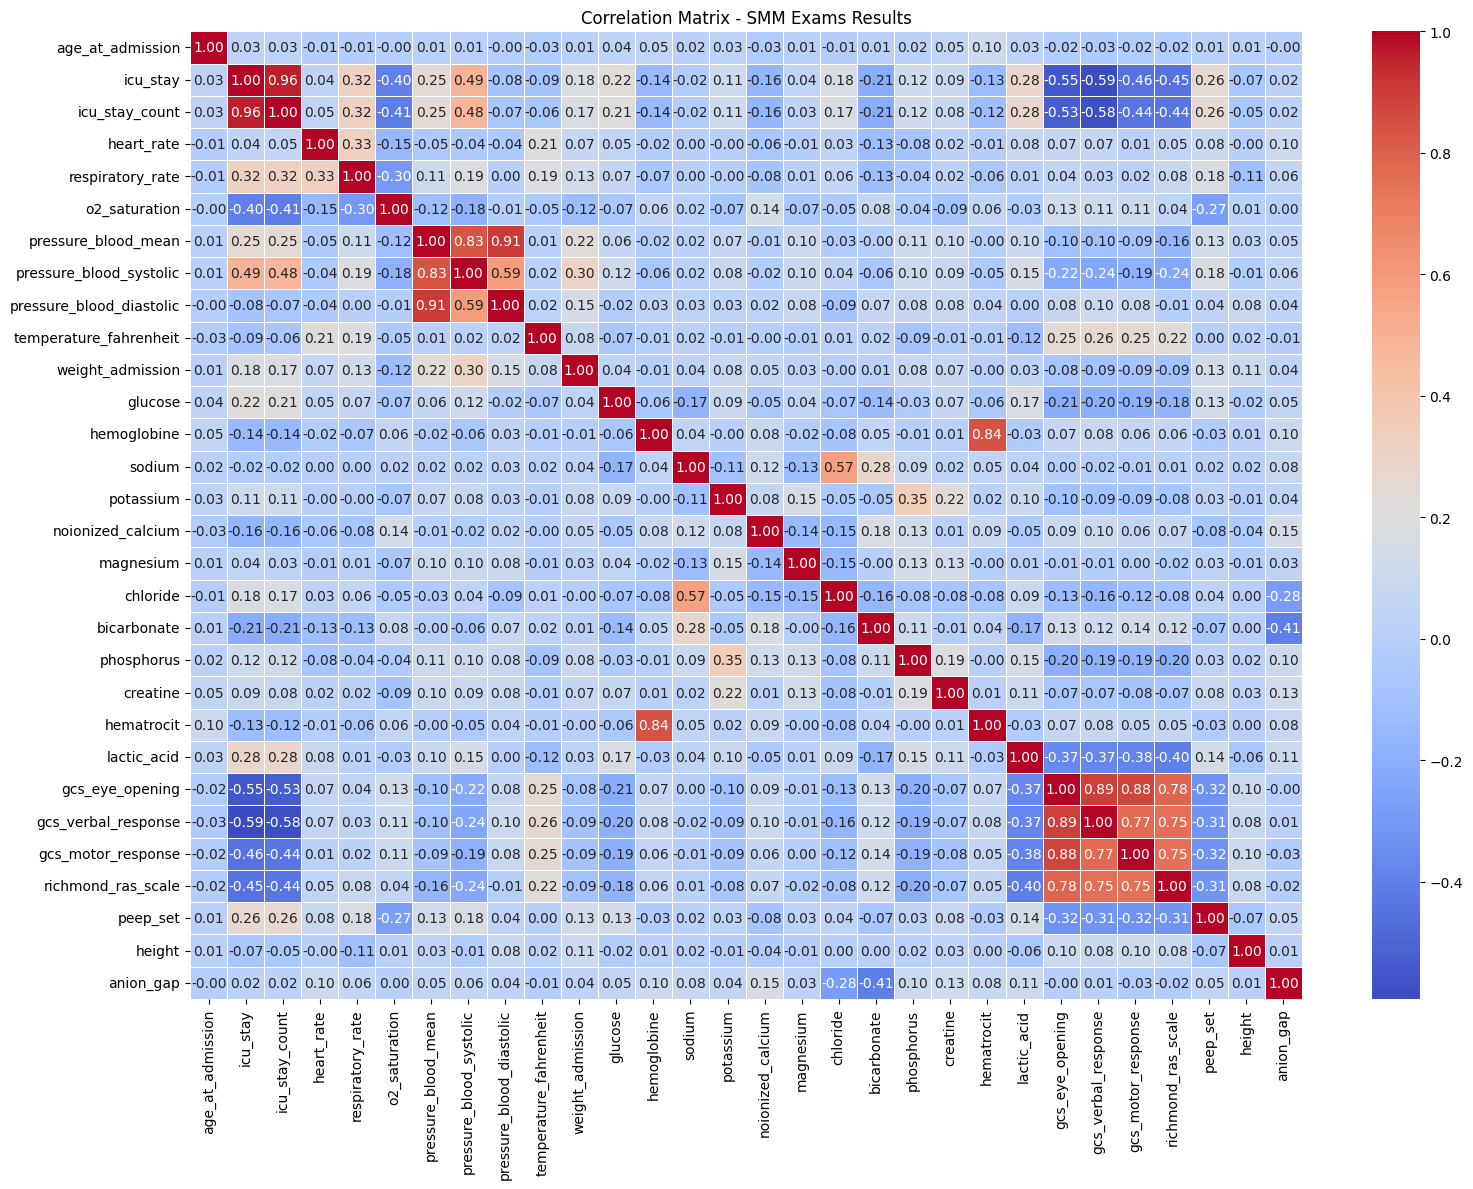

In [109]:
excluded = ['subject_id', 'hadm_id', 'stay_id', 'outcome_smm', 'is_delivery_hospitalization',
            'cardiac_count', 'renal_count', 'respiratory_count', 'hemorrhage_count',
            'sepsis_count', 'other_obstetric_count', 'other_medical_count']
df_correletion = df.drop(columns=[c for c in excluded if c in df.columns])

numeric_cols = df_correletion.select_dtypes(include='number')

correlation_matrix = numeric_cols.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix - SMM Exams Results')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'Fig_Correlacion_Matrix_SMM_Exams_Results.pdf'), format='pdf', bbox_inches='tight')
plt.savefig(os.path.join(FIG_DIR, 'Fig_Correlacion_Matrix_SMM_Exams_Results.png'), format='png', dpi=300, bbox_inches='tight')
plt.show()

In [110]:
gdg_cols  = [c for c in df.columns if c.startswith('gdg_')]
excl_cols = (['subject_id', 'hadm_id', 'stay_id', 'dob', 'outcome_smm', 'is_delivery_hospitalization']
             + gdg_cols
             + ['cardiac_count', 'renal_count', 'respiratory_count', 'hemorrhage_count',
                'sepsis_count', 'other_obstetric_count', 'other_medical_count'])

df_clinical = df.drop(columns=[c for c in excl_cols if c in df.columns])
clinical_num = df_clinical.select_dtypes(include='number')

corr_clinical = clinical_num.corr()

mask_upper = np.triu(np.ones_like(corr_clinical, dtype=bool), k=1)
high_corr_pairs = (
    corr_clinical
    .where(mask_upper)
    .stack()
    .reset_index()
)
high_corr_pairs.columns = ['feature_1', 'feature_2', 'r']
high_corr_pairs = high_corr_pairs[abs(high_corr_pairs['r']) >= 0.70].sort_values('r', ascending=False)

print(f"Pairs with |r| >= 0.70 among clinical measurement variables: {len(high_corr_pairs)}")
print()
print(high_corr_pairs.to_string(index=False))

Pairs with |r| >= 0.70 among clinical measurement variables: 10

          feature_1                feature_2        r
           icu_stay           icu_stay_count 0.958120
pressure_blood_mean pressure_blood_diastolic 0.906559
    gcs_eye_opening      gcs_verbal_response 0.891065
    gcs_eye_opening       gcs_motor_response 0.881765
        hemoglobine               hematrocit 0.838942
pressure_blood_mean  pressure_blood_systolic 0.832588
    gcs_eye_opening       richmond_ras_scale 0.782897
gcs_verbal_response       gcs_motor_response 0.772601
gcs_verbal_response       richmond_ras_scale 0.753587
 gcs_motor_response       richmond_ras_scale 0.746584


#### **8.1 Correlation decision -- clinical measurement variables**

As in Modelo A, the same physiologically expectable pairs are expected to reappear
(`hemoglobine` <-> `hematrocit`; `pressure_blood_mean` <-> systolic/diastolic) -- **to be re-verified**
once the query runs against the real database. The decision is the same: **keep all variables**.
Random Forest, XGBoost and Extra Trees are insensitive to multicollinearity; Logistic Regression is
protected by L2 regularisation. Dropping a variable from a pair would remove independently monitored
clinical signal with no modelling benefit.


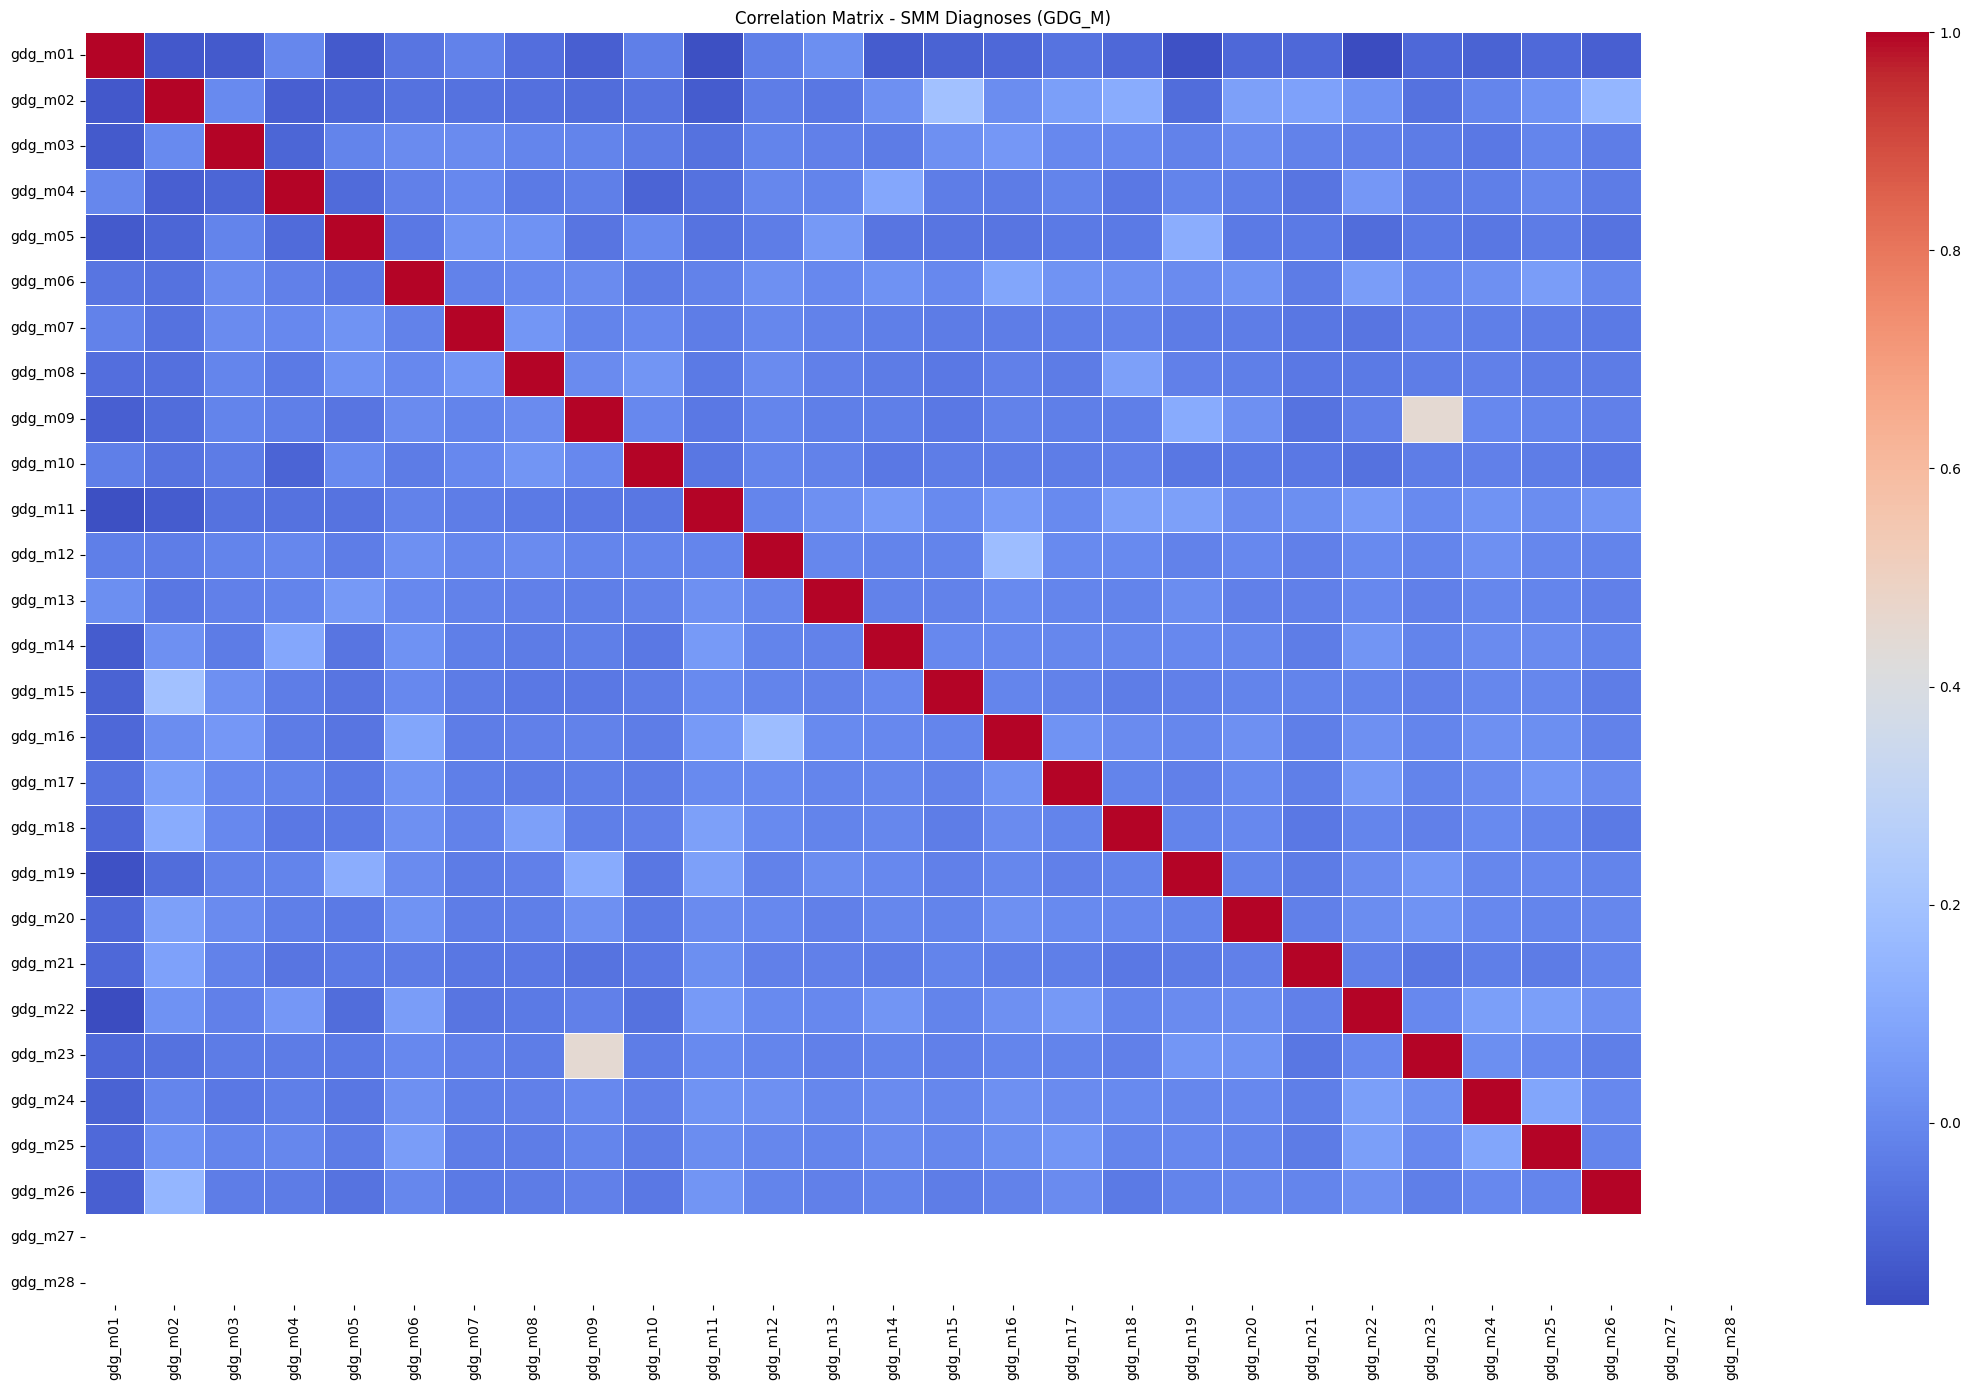

In [111]:
diagnosis_cols = [col for col in df.columns if col.startswith('gdg_') and df[col].dropna().isin([0, 1, True, False]).all()]

correlation_matrix = df[diagnosis_cols].corr()

plt.figure(figsize=(22, 14))
sns.heatmap(correlation_matrix, cmap='coolwarm', annot=False, linewidths=0.5)
plt.title('Correlation Matrix - SMM Diagnoses (GDG_M)')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'Fig_Correlacion_Matrix_SMM_Diagnoses.pdf'), format='pdf', bbox_inches='tight')
plt.savefig(os.path.join(FIG_DIR, 'Fig_Correlacion_Matrix_SMM_Diagnoses.png'), format='png', dpi=300, bbox_inches='tight')
plt.show()

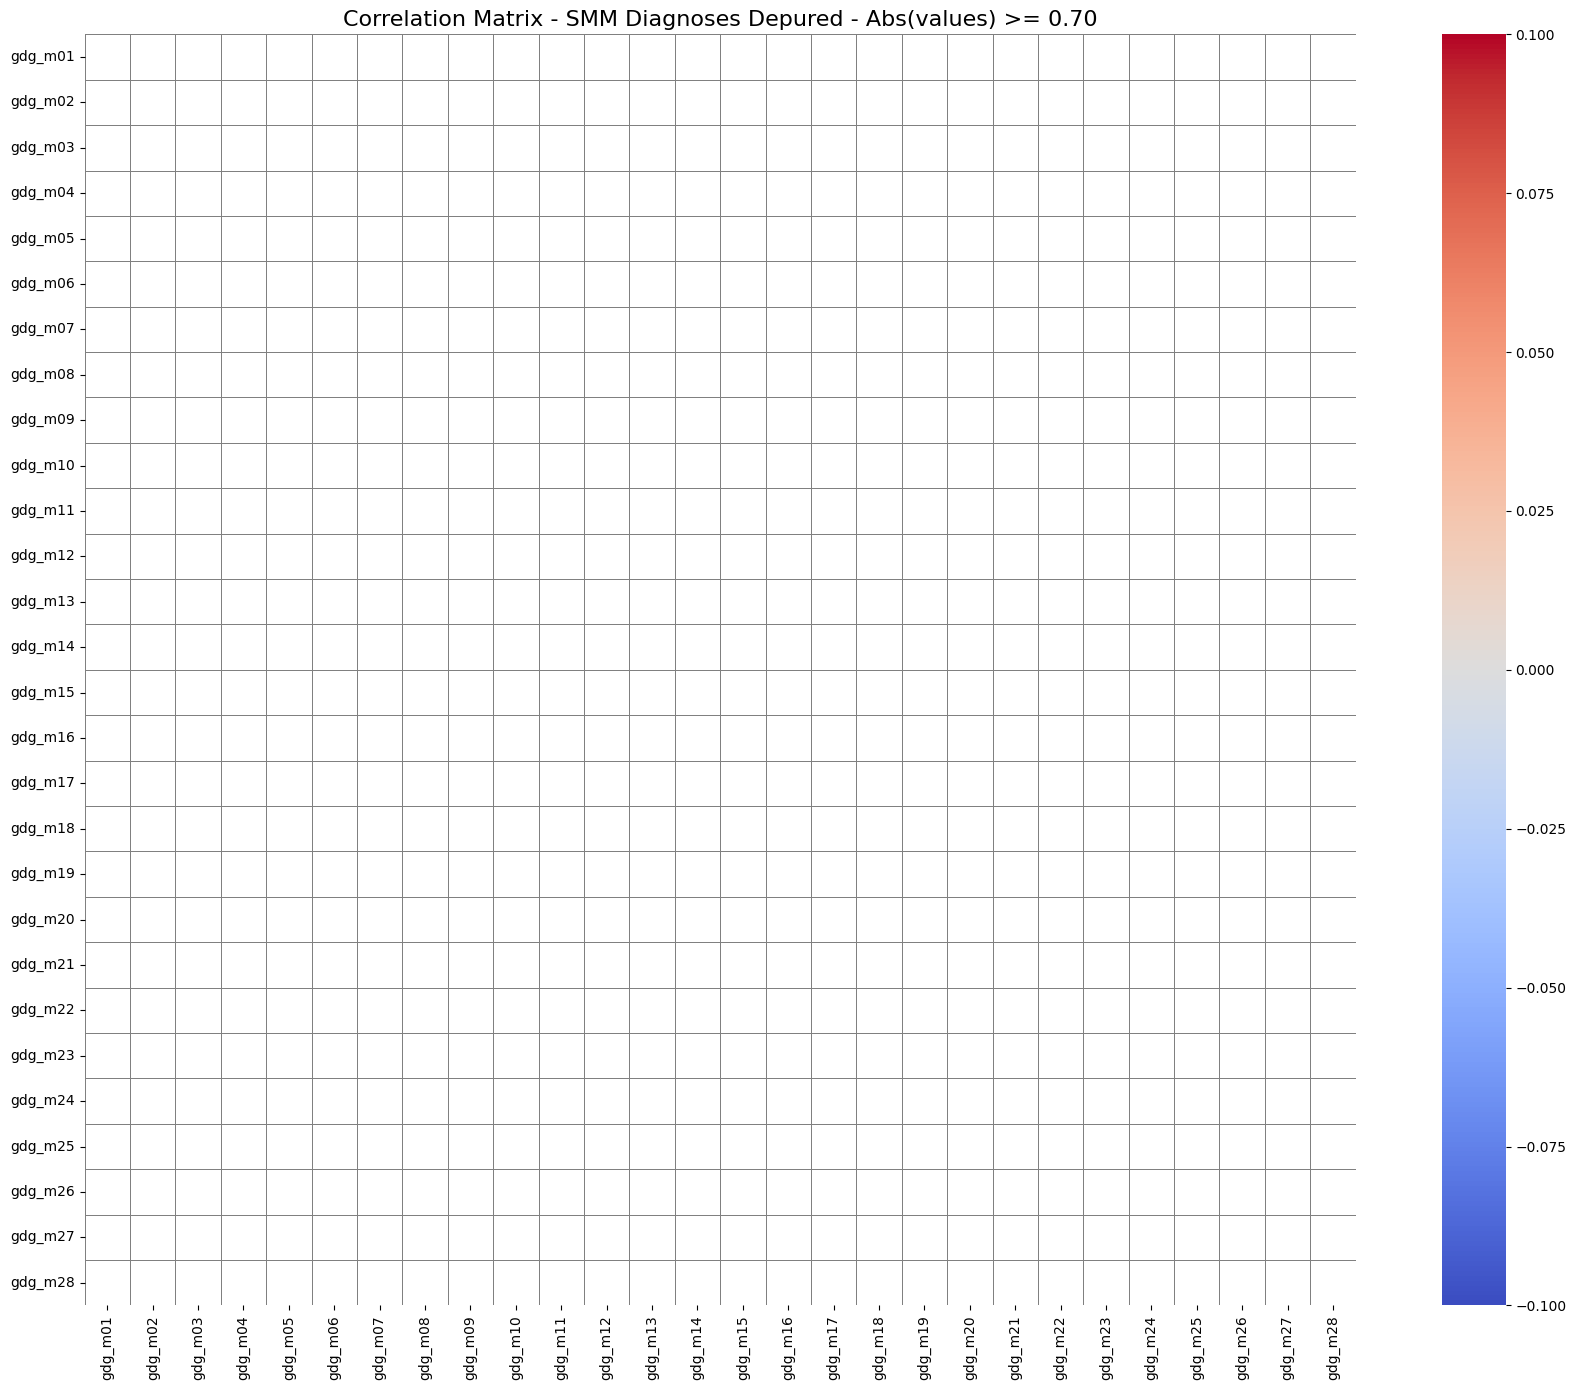

In [112]:
filtered_corr = correlation_matrix.copy()

mask_upper = np.triu(np.ones_like(filtered_corr, dtype=bool))
filtered_corr = filtered_corr.mask(mask_upper)

filtered_corr = filtered_corr.where((abs(filtered_corr) >= 0.70) & (abs(filtered_corr) < 1.0))

mask_to_plot = filtered_corr.isnull()

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)

    plt.figure(figsize=(18, 14))
    sns.heatmap(filtered_corr, mask=mask_to_plot, annot=True, fmt=".2f", cmap="coolwarm"
                , cbar=True, square=True, linewidths=0.5, linecolor='gray')
    plt.title("Correlation Matrix - SMM Diagnoses Depured - Abs(values) >= 0.70", fontsize=16)
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, 'Fig_Correlacion_Matrix_SMM_Diagnoses_Depured.pdf'), format='pdf', bbox_inches='tight')
    plt.savefig(os.path.join(FIG_DIR, 'Fig_Correlacion_Matrix_SMM_Diagnoses_Depured.png'), format='png', dpi=300, bbox_inches='tight')
    plt.show()

### **9. Scaling continuous variables**

Same two-strategy approach as Modelo A, chosen per variable based on skewness.

##### **9.1. Data distribution -- Histograms with density curve**

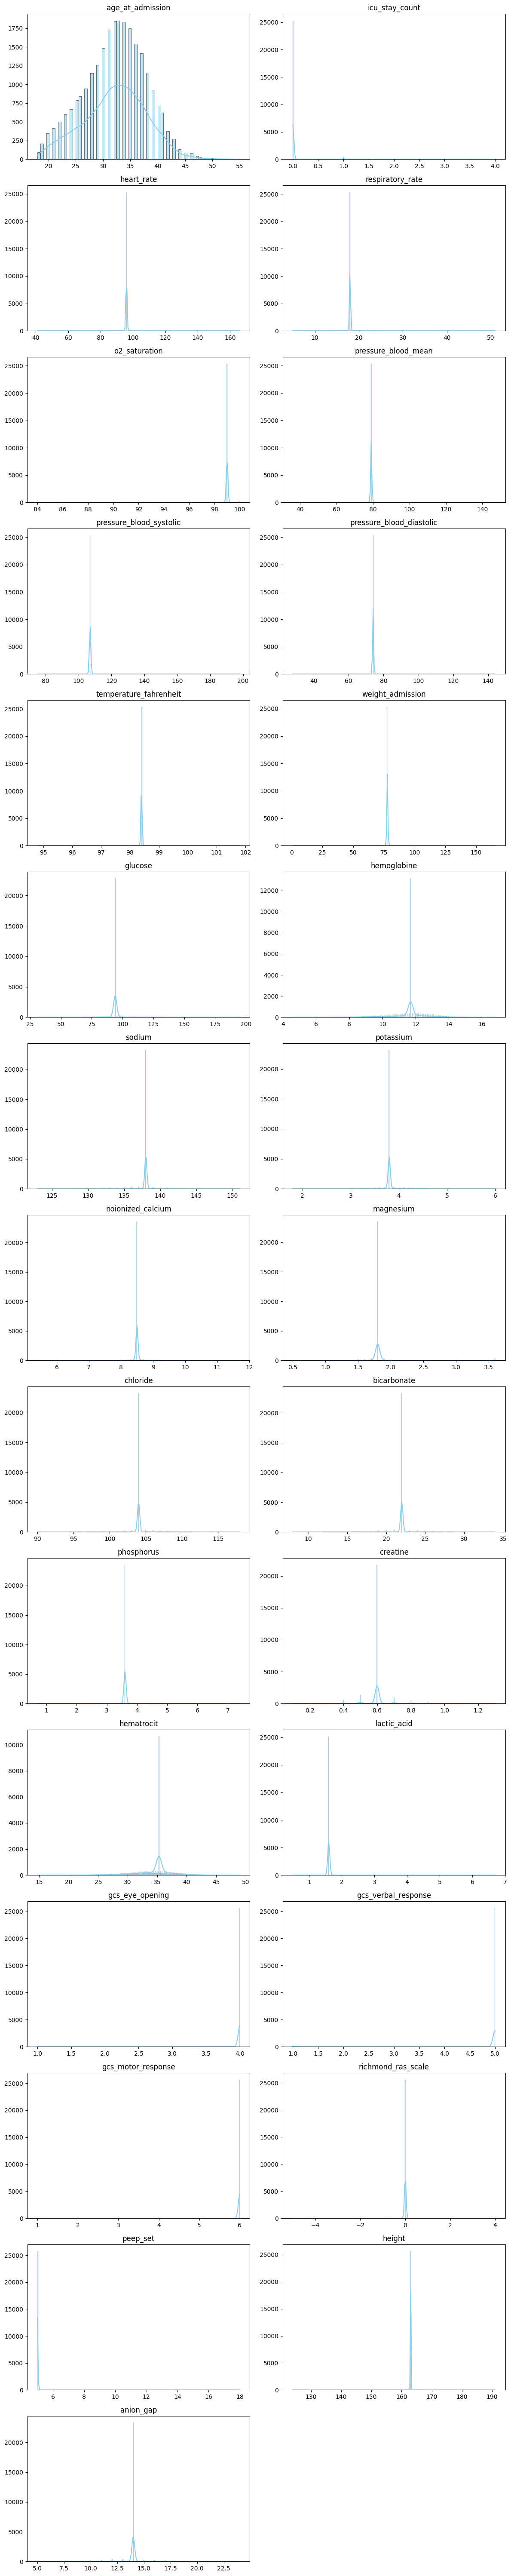

In [113]:
excluded_columns = ['subject_id', 'hadm_id', 'stay_id', 'outcome_smm', 'icu_stay', 'is_delivery_hospitalization',
                    'cardiac_count', 'renal_count', 'respiratory_count', 'hemorrhage_count',
                    'sepsis_count', 'other_obstetric_count', 'other_medical_count']
df_scalling = df.drop(columns=[c for c in excluded_columns if c in df.columns])

numeric_cols = df_scalling.select_dtypes(include='number').columns

cols_per_row = 2
total_plots = len(numeric_cols)
rows = math.ceil(total_plots / cols_per_row)
fig, axes = plt.subplots(rows, cols_per_row, figsize=(cols_per_row * 6, rows * 4))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.histplot(df_scalling[col].dropna(), kde=True, ax=axes[i], color='skyblue')
    axes[i].set_title(col)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

##### **9.2. Define the scaling technique for each continuous feature**

Misma regla: `|skew| > 1` -> `RobustScaler`; `|skew| <= 1` -> `MinMaxScaler`.


In [114]:
numeric_cols = df_scalling.select_dtypes(include=['number']).columns

def recommend_scaling(df_scalling, col):
    if df_scalling[col].skew() > 1 or df_scalling[col].skew() < -1:
        return 'RobustScaler', df_scalling[col].skew(), df_scalling[col].max() - df_scalling[col].min()
    else:
        return 'MinMaxScaler', df_scalling[col].skew(), df_scalling[col].max() - df_scalling[col].min()

recommendations = []

for col in numeric_cols:
    recomendation, skew, max_minus_min = recommend_scaling(df_scalling, col)
    recommendations.append({
                            'column': col
                            ,'technique': recomendation
                            ,'skew': skew
                            ,'max-min': max_minus_min
                            })

scaling_recommendations = pd.DataFrame(recommendations)
scaling_recommendations

,column,technique,skew,max-min
0,age_at_admission,MinMaxScaler,-0.125333,37.0
1,icu_stay_count,RobustScaler,8.735181,4.0
2,heart_rate,RobustScaler,3.417138,125.0
3,respiratory_rate,RobustScaler,12.289597,46.0
4,o2_saturation,RobustScaler,-18.137874,16.0
5,pressure_blood_mean,RobustScaler,8.104621,111.0
6,pressure_blood_systolic,RobustScaler,11.986161,123.0
7,pressure_blood_diastolic,RobustScaler,1.000780,116.0
8,temperature_fahrenheit,RobustScaler,-3.819398,7.0
9,weight_admission,RobustScaler,13.123426,164.5


In [115]:
# Export dataset (pre-scaling) for audit
df.to_excel('../data/df_cohort_smm_dataset.xlsx', index=False)

#### **9.3. Scaling**

In [116]:
df_scaled = df.copy()

for _, row in scaling_recommendations.iterrows():

    col = row['column']
    method = row['technique']

    if method == 'StandardScaler':
        scaler = StandardScaler()
    elif method == 'MinMaxScaler':
        scaler = MinMaxScaler()
    elif method == 'RobustScaler':
        scaler = RobustScaler()
    else:
        continue

    df_scaled[col + '_scaled'] = scaler.fit_transform(df[[col]])

df_scaled[[col + '_scaled' for col in scaling_recommendations['column'].head(5)]].head()

,age_at_admission_scaled,icu_stay_count_scaled,heart_rate_scaled,respiratory_rate_scaled,o2_saturation_scaled
0,0.432432,0.0,0.0,0.0,0.0
1,0.621622,0.0,0.0,0.0,0.0
2,0.378378,0.0,0.0,0.0,0.0
3,0.324324,0.0,0.0,0.0,0.0
4,0.351351,0.0,0.0,0.0,0.0


In [117]:
df_scaled.to_excel("../data/df_scaled_cohort_smm_dataset.xlsx", index=False)
print("Scalling complete. Shape:", df_scaled.shape)

Scalling complete. Shape: (25736, 136)


### **10. Build model dataset**

Same assembly rule as Modelo A -- identifiers out, raw numeric columns out in favour
of their `_scaled` versions, an explicit zero-variance check (`gender` is constant `F` by construction)
-- **plus the explicit exclusion of outcome-derived columns**: the 7 per-category counts
(`*_count`) and `primary_smm_category` **do not go into `X`** because they are components of the target
itself (see the information-leakage warning, Section 2.1/2.7). `is_delivery_hospitalization` **is**
kept in `X` -- it is a feature of the admission type, logically independent of whether SMM was detected.


In [118]:
id_cols = ["subject_id","hadm_id","stay_id","dob"]
raw_numeric = [name for name, _ in [
    ("heart_rate",None),("respiratory_rate",None),("o2_saturation",None),
    ("pressure_blood_mean",None),("pressure_blood_systolic",None),("pressure_blood_diastolic",None),
    ("temperature_fahrenheit",None),("weight_admission",None),("glucose",None),("hemoglobine",None),
    ("sodium",None),("potassium",None),("noionized_calcium",None),("magnesium",None),("chloride",None),
    ("bicarbonate",None),("phosphorus",None),("creatine",None),("hematrocit",None),("lactic_acid",None),
    ("gcs_eye_opening",None),("gcs_verbal_response",None),("gcs_motor_response",None),
    ("richmond_ras_scale",None),("peep_set",None),("height",None),("anion_gap",None),
    ("age_at_admission",None),("icu_stay_count",None)
]]

# Outcome-derived columns -- excluded from X due to information leakage (see Section 2.1/2.7).
# Kept separately for the complementary analysis in Section 15.
leakage_cols = ["cardiac_count", "renal_count", "respiratory_count", "hemorrhage_count",
                "sepsis_count", "other_obstetric_count", "other_medical_count",
                "primary_smm_category"]

df_category_reference = df_scaled[["subject_id", "hadm_id", "outcome_smm"] +
                                   [c for c in leakage_cols if c in df_scaled.columns]].copy()

df_model = df_scaled.sort_values('subject_id').reset_index(drop=True)

# Delivery flag kept ONLY as a reference to evaluate the delivery-hospitalization subset (Section 12.6);
# it is NOT a predictor. Index is aligned with df_model / X / X_test.
df_delivery_ref = df_model[["is_delivery_hospitalization"]].copy()

# --- Leakage control (added 2026-10-09) -------------------------------------------------------
# * gdg_m01..gdg_m28 are built from the admission's top-4 ICD diagnoses, i.e. from the same coded
#   diagnoses (sepsis, hemorrhage, eclampsia, cardiac arrest...) that DEFINE the SMM outcome.
#   Using them as predictors lets the model read the answer. Excluded from the main model.
#   Set INCLUDE_GDG_FEATURES = True only for a documented sensitivity analysis.
# * is_delivery_hospitalization (and its _scaled copy) comes from discharge-coded Z37/O80/O82
#   diagnoses -> not available at admission; excluded as a predictor.
INCLUDE_GDG_FEATURES = False
gdg_cols_all = [c for c in df_model.columns if c.startswith("gdg_")]
delivery_cols = [c for c in df_model.columns if c.startswith("is_delivery_hospitalization")]
leakage_cols = leakage_cols + delivery_cols + ([] if INCLUDE_GDG_FEATURES else gdg_cols_all)

col_to_drop = id_cols + [c for c in raw_numeric if c in df_scaled.columns] + [c for c in leakage_cols if c in df_scaled.columns]
df_model = df_model.drop(columns=[c for c in col_to_drop if c in df_scaled.columns])
df_model = df_model.reset_index(drop=True)

# Drop zero-variance columns (e.g. gender_* dummies, constant by cohort construction)
constant_cols = [c for c in df_model.columns if c != "outcome_smm" and df_model[c].nunique(dropna=False) <= 1]
if constant_cols:
    print(f"Dropping {len(constant_cols)} zero-variance columns: {constant_cols}")
    df_model = df_model.drop(columns=constant_cols)

# rename outcome for consistency with the modelling helper functions below
df_model = df_model.rename(columns={"outcome_smm": "outcome"})

print(f"Model Features: {len(df_model.columns) - 1}")
print(df_model.columns.tolist())

Model Features: 65
['outcome', 'icu_stay', 'ethnicity_group_AFRO_DESC', 'ethnicity_group_ASIAN', 'ethnicity_group_HISPANIC', 'ethnicity_group_INDIAN_USA', 'ethnicity_group_PACIFIC_ISL', 'ethnicity_group_UNKNOWN', 'ethnicity_group_WHITE_UE', 'ethnicity_group_WHITE_USA', 'insurance_MEDICAID', 'insurance_MEDICARE', 'insurance_NO_CHARGE', 'insurance_OTHERS', 'insurance_PRIVATE', 'language_group_AFROASIAN_LANG', 'language_group_GERMANIC_LANG', 'language_group_INDOEUR_LANG', 'language_group_NATIVE_LANG', 'language_group_ORIENTAL_LANG', 'language_group_OTHERS_LANG', 'language_group_ROMANCE_LANG', 'language_group_SIGN_LANG', 'language_group_SLAVIC_LANG', 'admission_type_AMBULATORY_OBSERVATION', 'admission_type_DIRECT_EMER.', 'admission_type_DIRECT_OBSERVATION', 'admission_type_ELECTIVE', 'admission_type_EU_OBSERVATION', 'admission_type_EW_EMER.', 'admission_type_OBSERVATION_ADMIT', 'admission_type_SURGICAL_SAME_DAY_ADMISSION', 'admission_type_URGENT', 'admission_location_group_EMERGENCY', 'adm

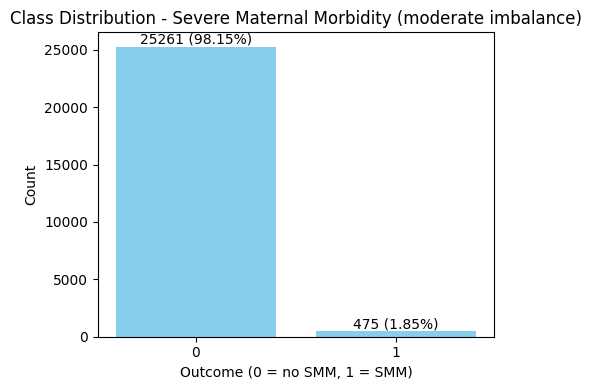

In [119]:
count_y = df_model['outcome'].value_counts().sort_index()

total = count_y.sum()
percentages = (count_y / total) * 100

plt.figure(figsize=(5, 4))

bars = plt.bar(count_y.index.astype(str), count_y.values, color='skyblue')

for bar, cantidad, percentaje in zip(bars, count_y.values, percentages.values):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                f'{cantidad} ({percentaje:.2f}%)',
                ha='center', va='bottom', fontsize=10
            )

plt.title('Class Distribution - Severe Maternal Morbidity (moderate imbalance)')
plt.xlabel('Outcome (0 = no SMM, 1 = SMM)')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### **11. Train / Test Split -- Handling a Moderate (not extreme) Class Imbalance**

Unlike Modelo A (41 positives out of 25,736, ~0.16%), the observed SMM prevalence is
**1.846%** (475 positives; 2.845% among delivery hospitalizations, above the published 58-88 per 10,000 deliveries). This is
still a class imbalance, but **no longer extreme**: with 475 positive cases
in the full dataset, a stratified 80/20 split leaves 95 positive test cases, substantially
more than Modelo A's 8 -- point estimates of minority-class recall/precision are therefore
considerably more stable.

**Best practices that are kept (not because the imbalance is "extreme", but because they remain the
right practice for any non-trivial imbalance):**

1. **Stratified 80/20 split** as an illustrative final evaluation (same as Modelo A and the
   neonatal model).
2. **`StratifiedKFold` (k=5)** as the primary performance evidence -- each fold preserves SMM
   prevalence, giving a reasonable number of positive cases per fold.
3. **Imbalance-robust metrics**: `average_precision` (PR-AUC) as `GridSearchCV`'s main
   metric, reported alongside ROC-AUC, recall, F1 and balanced accuracy.
4. **`class_weight="balanced"` / `"balanced_subsample"`** (Random Forest, Extra Trees), **`scale_pos_weight`**
   (XGBoost), **`class_weight="balanced"`** (Logistic Regression) -- same as Modelo A. `SMOTE` remains
   available (imported in Section 1) as an optional sensitivity analysis, now with a considerably larger
   base of real cases to synthesise from more reasonably than with Modelo A's ~33 training positives.

**Unlike Modelo A's note**, here the number of positive cases (475) DOES
allow reporting the results as **more robust evidence** (still single-center and ICD-based), and not merely as an exploratory/hypothesis-generating finding -- see the
comparison table in Section 0.2.

In [120]:
X = df_model.drop(columns=["outcome"])
y = df_model["outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")
print(f"Prevalencia positiva -- Train: {y_train.mean():.5f} ({y_train.sum()} casos)  |  "
      f"Test: {y_test.mean():.5f} ({y_test.sum()} casos)")

# Primary evidence: Stratified K-Fold (documented in the markdown above)
N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

cv_scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "recall": "recall",
    "f1": "f1",
    "balanced_accuracy": "balanced_accuracy",
}

def run_cv_diagnostics(model, X_data, y_data, label):
    """Sanity-check cross-validated performance before/alongside GridSearchCV tuning."""
    scores = cross_validate(model, X_data, y_data, cv=skf, scoring=cv_scoring, n_jobs=-1)
    summary = {metric: (np.mean(scores[f"test_{metric}"]), np.std(scores[f"test_{metric}"]))
               for metric in cv_scoring}
    print(f"--- {label} ({N_SPLITS}-fold Stratified CV) ---")
    for metric, (m, s) in summary.items():
        print(f"  {metric:20s}: {m:.3f} +/- {s:.3f}")
    return summary

Train: (20588, 65)  |  Test: (5148, 65)
Prevalencia positiva -- Train: 0.01846 (380 casos)  |  Test: 0.01845 (95 casos)


### **12. Run Models**

Same five models as Modelo A and the neonatal model (Random Forest, XGBoost, Extra Trees, Logistic
Regression, Stacking), trained with `GridSearchCV` (5-fold stratified, `n_jobs=-1`), optimising
`'average_precision'` as the main metric (more informative than `'f1'` under imbalance, same
criterion as Modelo A). Since a notably larger number of training-positive cases is expected here
than in Modelo A, the hyperparameter grids are left **slightly wider** than Modelo A's
(reasonable now that there is more data to support the search without overfitting the search itself).

`run_model`, `plot_roc` and `plot_pr` are reused unchanged from the pattern already validated in
`maternal_mortality_models.ipynb`.


In [121]:
def run_model(p_model, p_param_grid, p_X_train, p_y_train, p_X_test, p_y_test, title_model, nombre_imagen,
              scoring='average_precision'):

    with open(os.devnull, 'w') as f, redirect_stdout(f):

        grid_search = GridSearchCV(estimator=p_model
                                   , param_grid=p_param_grid
                                   , scoring=scoring
                                   , cv=skf
                                   , verbose=1
                                   , n_jobs=-1
                                   )

        grid_search.fit(p_X_train, p_y_train)

    best_model = grid_search.best_estimator_

    best_params_formatted = ', '.join(f'{key}: {value}' for key, value in grid_search.best_params_.items())

    # Hard labels -> classification_report / confusion matrix ONLY.
    y_pred_model = best_model.predict(p_X_test)
    # Probability scores -> ROC / PR curves and AUC / AP (fix 2026-10-09: previously the hard labels
    # were passed to roc_curve / precision_recall_curve, which collapses the curve to one threshold).
    y_proba_model = best_model.predict_proba(p_X_test)[:, 1]

    report_dict = classification_report(p_y_test, y_pred_model, output_dict=True)
    report_df = pd.DataFrame(report_dict).transpose()
    report_df = report_df.round(2)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    sns.heatmap(report_df.iloc[:-1, :-1], annot=True, cmap="YlGnBu", cbar=False, ax=axes[0])
    axes[0].set_title("Best hyperparams: " + best_params_formatted, fontsize=8)
    axes[0].set_ylabel("Classes")
    axes[0].set_xlabel("Metrics")
    axes[0].tick_params(axis='y', rotation=0)

    cm = confusion_matrix(p_y_test, y_pred_model)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_model.classes_)
    disp.plot(cmap='Blues', ax=axes[1], colorbar=False)
    axes[1].set_title("Confusion Matrix", fontsize=8)

    fig.suptitle(title_model, fontsize=12, weight='bold')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.savefig(os.path.join(FIG_DIR, nombre_imagen + '.pdf'), format='pdf', bbox_inches='tight')
    plt.savefig(os.path.join(FIG_DIR, nombre_imagen + '.png'), format='png', dpi=300, bbox_inches='tight')
    plt.show()

    return best_model, y_pred_model, y_proba_model


def plot_roc(y_test, y_score, title, nombre_imagen):
    # y_score = predicted PROBABILITIES of the positive class, not hard labels
    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_auc = auc(fpr, tpr)
    plt.figure(figsize=(5,4))
    plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
    plt.plot([0,1],[0,1],"k--")
    plt.xlabel("FPR"); plt.ylabel("TPR")
    plt.title(f"ROC -- {title}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, nombre_imagen + '.pdf'), format='pdf', bbox_inches='tight')
    plt.savefig(os.path.join(FIG_DIR, nombre_imagen + '.png'), format='png', dpi=300, bbox_inches='tight')
    plt.show()
    return roc_auc


def plot_pr(y_test, y_score, title, nombre_imagen):
    # y_score = predicted PROBABILITIES of the positive class, not hard labels
    precision, recall, _ = precision_recall_curve(y_test, y_score)
    avg_precision = average_precision_score(y_test, y_score)
    plt.figure(figsize=(5,4))
    plt.plot(recall, precision, label=f"AP = {avg_precision:.3f}")
    baseline = y_test.mean()
    plt.axhline(baseline, color="k", linestyle="--", label=f"Baseline (prevalence) = {baseline:.4f}")
    plt.xlabel("Recall"); plt.ylabel("Precision")
    plt.title(f"Precision-Recall -- {title}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, nombre_imagen + '.pdf'), format='pdf', bbox_inches='tight')
    plt.savefig(os.path.join(FIG_DIR, nombre_imagen + '.png'), format='png', dpi=300, bbox_inches='tight')
    plt.show()
    return avg_precision

#### **12.1. Random Forest**

--- Random Forest (pre-tuning sanity check) (5-fold Stratified CV) ---
  roc_auc             : 0.845 +/- 0.019
  average_precision   : 0.112 +/- 0.010
  recall              : 0.053 +/- 0.017
  f1                  : 0.062 +/- 0.023
  balanced_accuracy   : 0.520 +/- 0.009


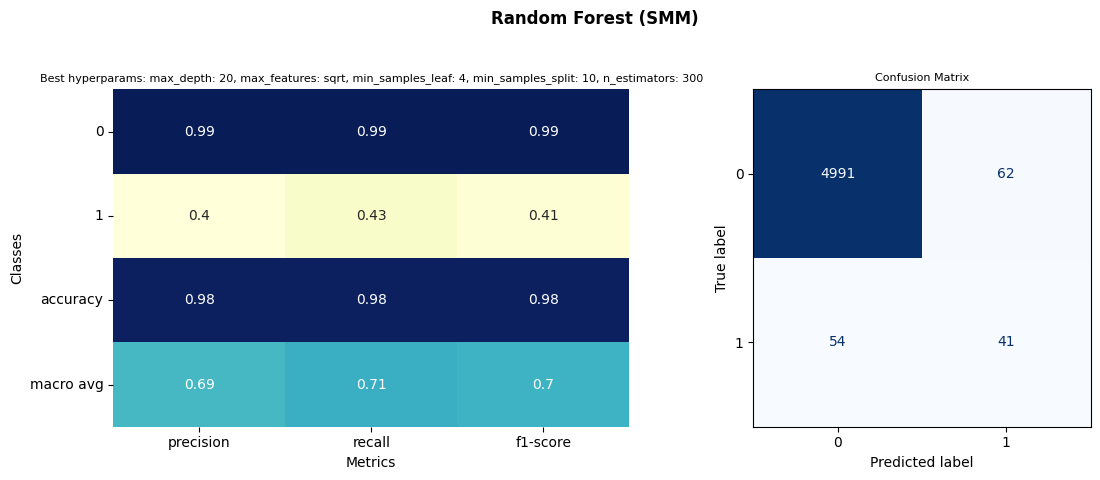

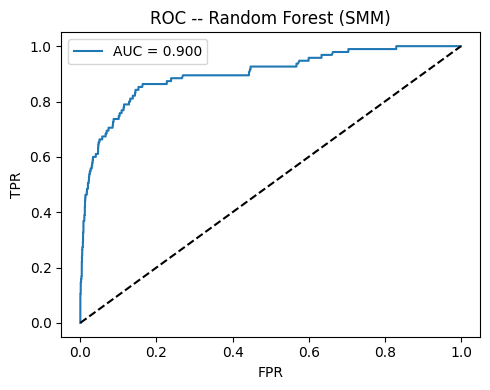

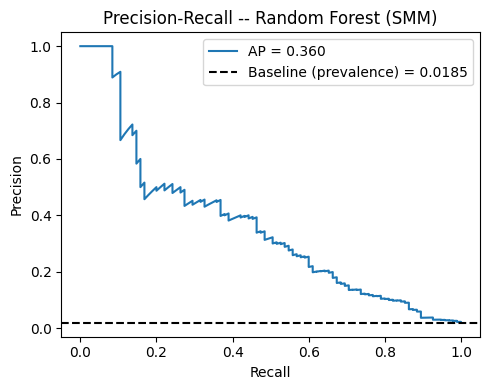

In [122]:
model_rf = RandomForestClassifier(class_weight="balanced_subsample", random_state=42)

param_grid_rf = {
    "n_estimators": [300, 500],
    "max_depth": [15, 20, 30, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt"],
}

run_cv_diagnostics(model_rf, X_train, y_train, "Random Forest (pre-tuning sanity check)")

best_model_rf, y_pred_rf, y_proba_rf = run_model(
    model_rf, param_grid_rf, X_train, y_train, X_test, y_test, "Random Forest (SMM)", "Fig_RF_SMM_Model"
)
auc_rf = plot_roc(y_test, y_proba_rf, "Random Forest (SMM)", "Fig_ROC_RF_SMM")
ap_rf  = plot_pr(y_test, y_proba_rf, "Random Forest (SMM)", "Fig_PR_RF_SMM")

Original features:  65
Selected features: 36
Dropped features:    29
Importance threshold: 0.00446


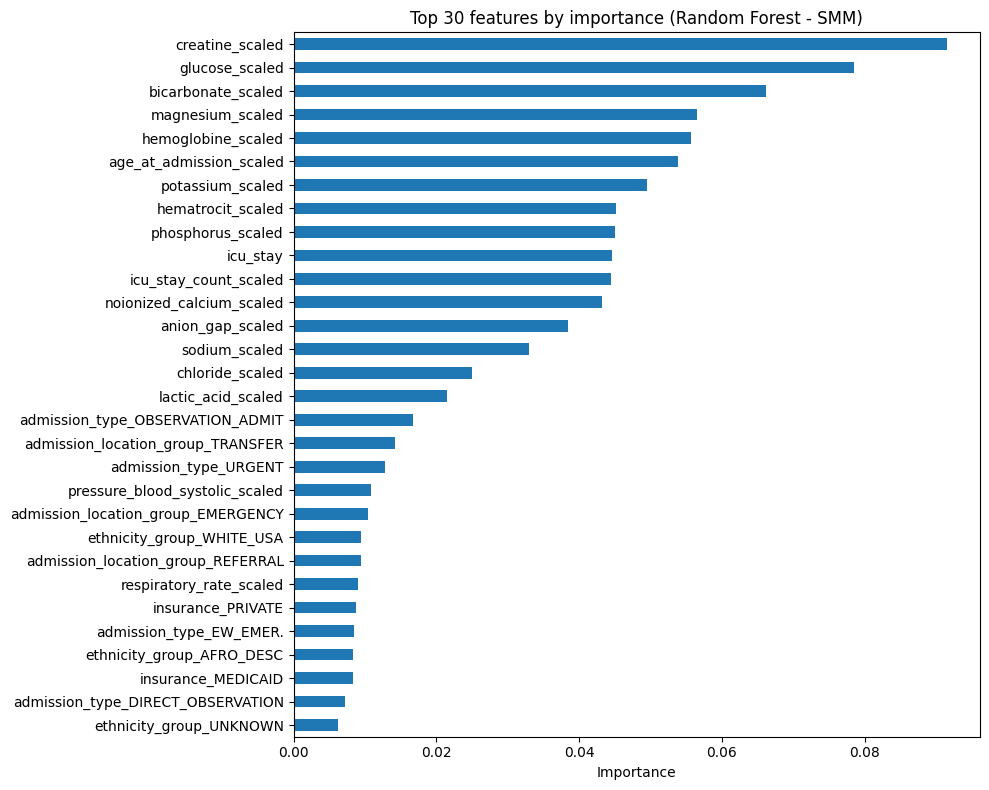

In [123]:
importances = pd.Series(best_model_rf.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)

threshold = importances.mean() - 0.5 * importances.std()
selected_features = importances[importances >= threshold].index.tolist()
dropped_features  = importances[importances <  threshold].index.tolist()

print(f"Original features:  {len(importances)}")
print(f"Selected features: {len(selected_features)}")
print(f"Dropped features:    {len(dropped_features)}")
print(f"Importance threshold: {threshold:.5f}")

plt.figure(figsize=(10,8))
importances.head(30).sort_values().plot(kind="barh")
plt.title("Top 30 features by importance (Random Forest - SMM)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'Top_30_Feature_SMM.pdf'), format='pdf', bbox_inches='tight')
plt.savefig(os.path.join(FIG_DIR, 'Top_30_Feature_SMM.png'), format='png', dpi=300, bbox_inches='tight')
plt.show()

#### **12.2. XGBoost**

scale_pos_weight: 53.2


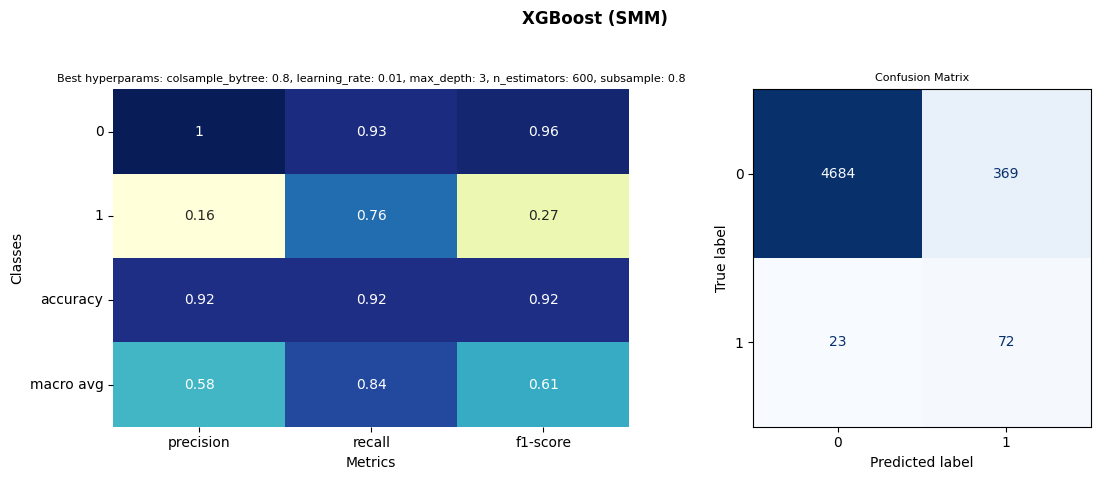

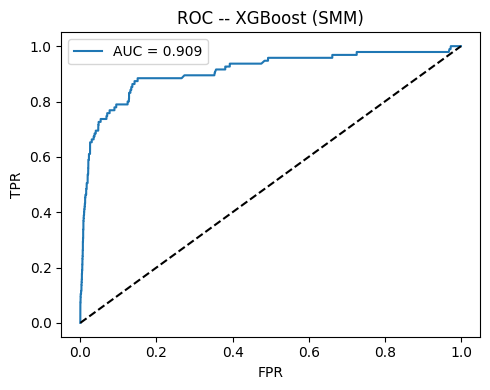

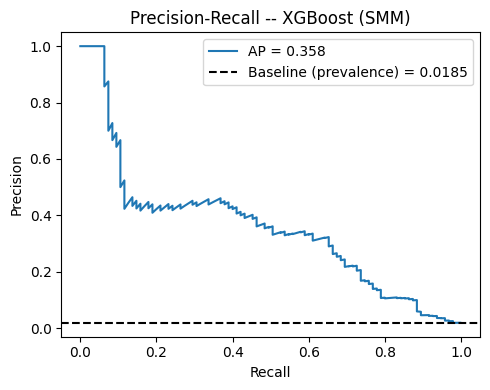

In [124]:
scale_pos_weight = len(y_train[y_train == 0]) / len(y_train[y_train == 1])
print(f"scale_pos_weight: {scale_pos_weight:.1f}")

model_xgb = XGBClassifier(
    scale_pos_weight=scale_pos_weight, eval_metric="logloss", random_state=42
)

param_grid_xgb = {
    "n_estimators": [200, 400, 600],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
}

best_model_xgb, y_pred_xgb, y_proba_xgb = run_model(
    model_xgb, param_grid_xgb,
    X_train, y_train, X_test, y_test,
    "XGBoost (SMM)", "Fig_XGBoost_SMM_Model"
)
auc_xgb = plot_roc(y_test, y_proba_xgb, "XGBoost (SMM)", "Fig_ROC_XGBoost_SMM")
ap_xgb  = plot_pr(y_test, y_proba_xgb, "XGBoost (SMM)", "Fig_PR_XGBoost_SMM")

#### **12.3. Extra Trees**

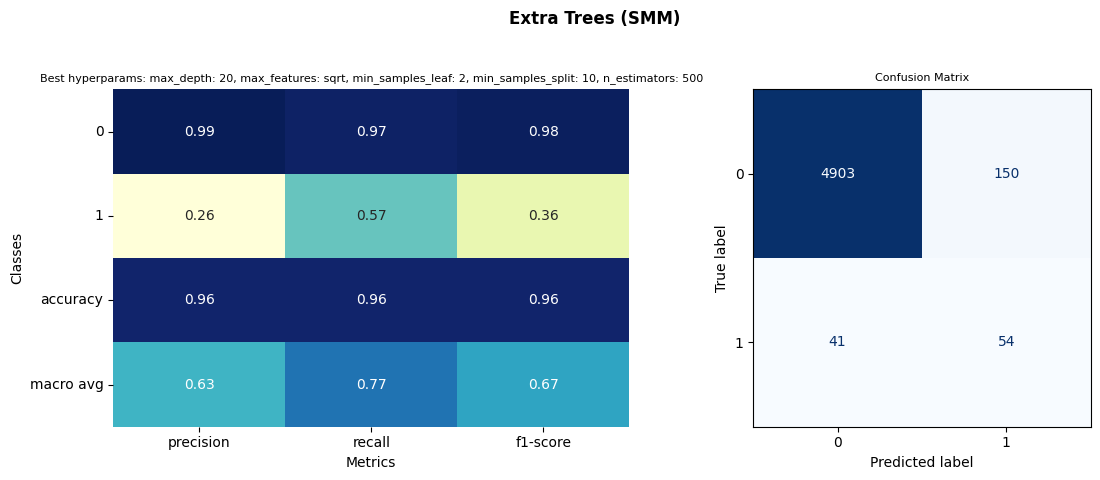

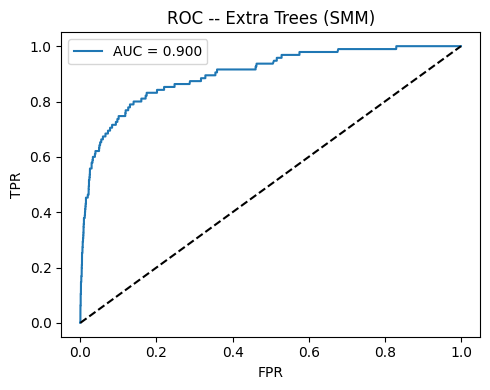

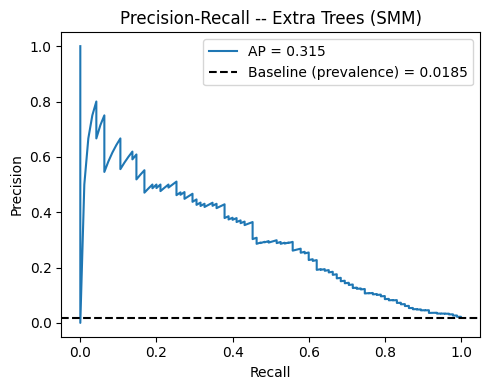

In [125]:
model_et = ExtraTreesClassifier(random_state=42, n_jobs=-1, class_weight="balanced")

param_grid_et = {
    "n_estimators": [300, 400, 500],
    "max_depth": [None, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt"],
}

best_model_et, y_pred_et, y_proba_et = run_model(
    model_et, param_grid_et,
    X_train, y_train, X_test, y_test,
    "Extra Trees (SMM)", "Fig_Extra_Tree_SMM_Model"
)
auc_et = plot_roc(y_test, y_proba_et, "Extra Trees (SMM)", "Fig_ROC_Extra_Trees_SMM")
ap_et  = plot_pr(y_test, y_proba_et, "Extra Trees (SMM)", "Fig_PR_Extra_Trees_SMM")

#### **12.4. Logistic Regression**

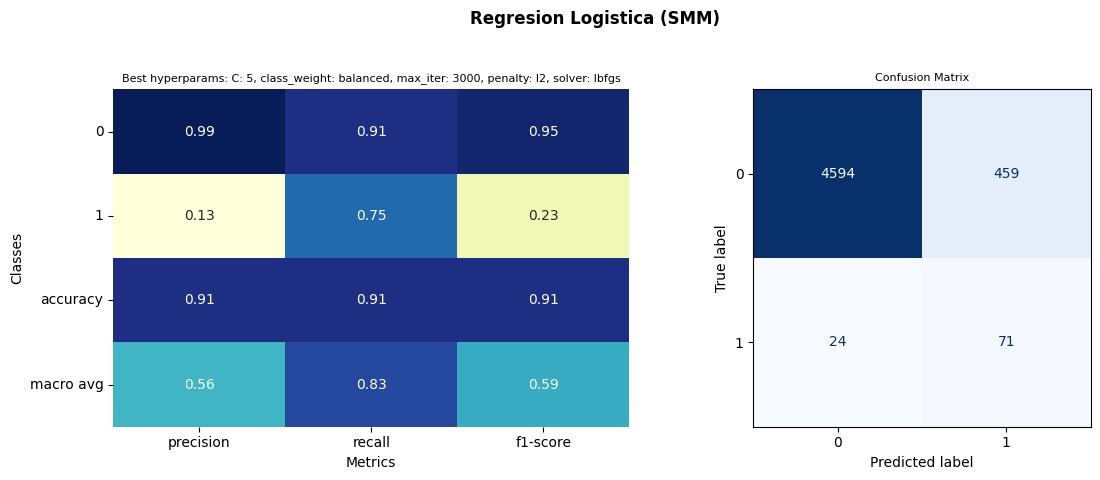

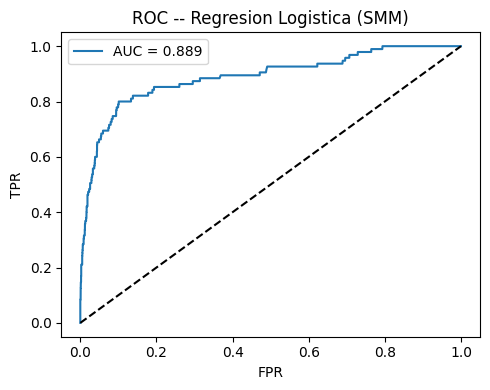

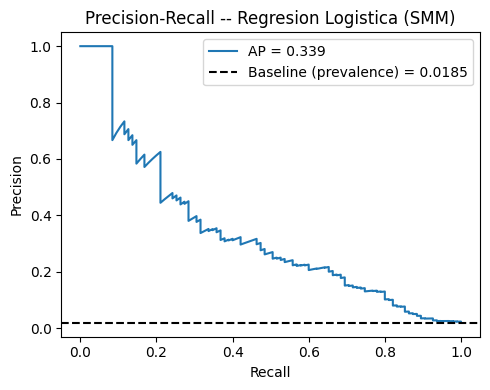

In [126]:
model_rl = LogisticRegression()

param_grid_rl = {
    "penalty": ["l2"],
    "C": [0.01, 0.1, 1, 5, 10],
    "solver": ["lbfgs", "saga"],
    "max_iter": [3000],
    "class_weight": ["balanced"],
}

best_model_rl, y_pred_rl, y_proba_rl = run_model(
    model_rl, param_grid_rl,
    X_train, y_train, X_test, y_test,
    "Regresion Logistica (SMM)", "Fig_RL_SMM_Model"
)
auc_rl = plot_roc(y_test, y_proba_rl, "Regresion Logistica (SMM)","Fig_ROC_RL_SMM")
ap_rl  = plot_pr(y_test, y_proba_rl, "Regresion Logistica (SMM)", "Fig_PR_RL_SMM")

#### **12.5. Stacked Ensemble Model**

Same architecture as Modelo A: the four already-fitted base models feed a `StackingClassifier`
whose meta-learner is an L2-regularised `LogisticRegression` with `class_weight`.


In [127]:
estimators = [
    ("rf",  best_model_rf),
    ("xgb", best_model_xgb),
    ("et",  best_model_et),
    ("rl",  best_model_rl),
]

stacking_clf = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(
        penalty="l2", C=0.1, solver="lbfgs",
        max_iter=5000, class_weight="balanced", random_state=42
    ),
    cv=skf, n_jobs=-1
)

stacking_clf.fit(X_train, y_train)
y_pred_stack  = stacking_clf.predict(X_test)
y_proba_stack = stacking_clf.predict_proba(X_test)[:, 1]

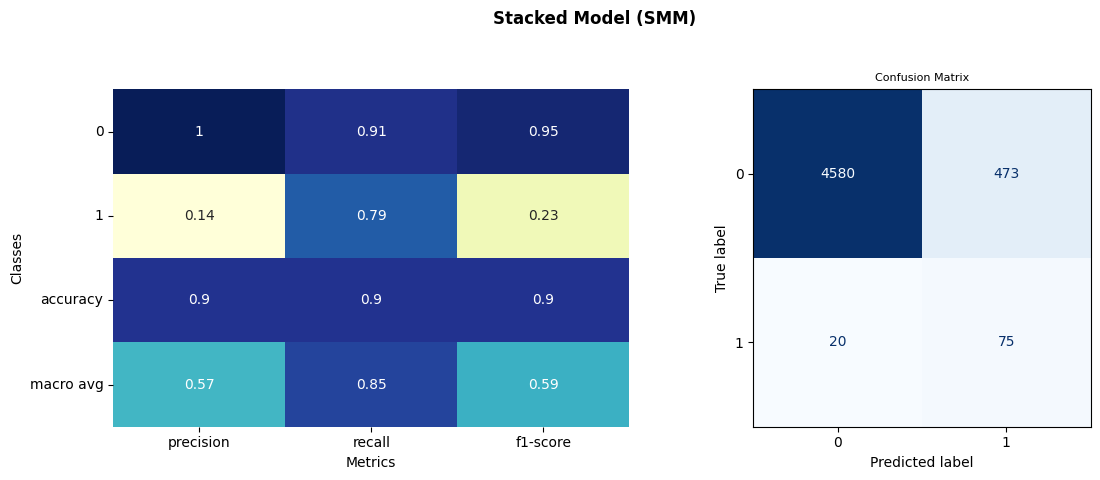

In [128]:
report_dict = classification_report(y_test, y_pred_stack, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()
report_df = report_df.round(2)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(report_df.iloc[:-1, :-1], annot=True, cmap="YlGnBu", cbar=False, ax=axes[0])
axes[0].set_title("", fontsize=8)
axes[0].set_ylabel("Classes")
axes[0].set_xlabel("Metrics")
axes[0].tick_params(axis='y', rotation=0)

cm = confusion_matrix(y_test, y_pred_stack)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=stacking_clf.classes_)
disp.plot(cmap='Blues', ax=axes[1], colorbar=False)
axes[1].set_title("Confusion Matrix", fontsize=8)

fig.suptitle("Stacked Model (SMM)", fontsize=12, weight='bold')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig(os.path.join(FIG_DIR, 'Fig_Stacked_SMM_Model.pdf'), format='pdf', bbox_inches='tight')
plt.savefig(os.path.join(FIG_DIR, 'Fig_Stacked_SMM_Model.png'), format='png', dpi=300, bbox_inches='tight')
plt.show()

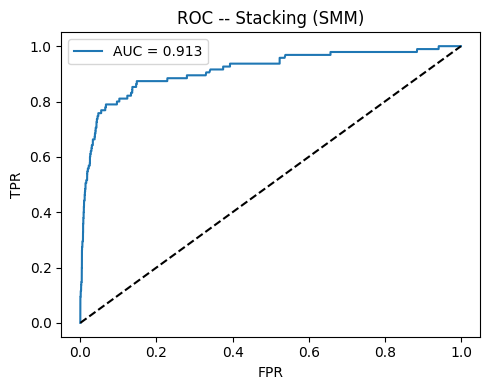

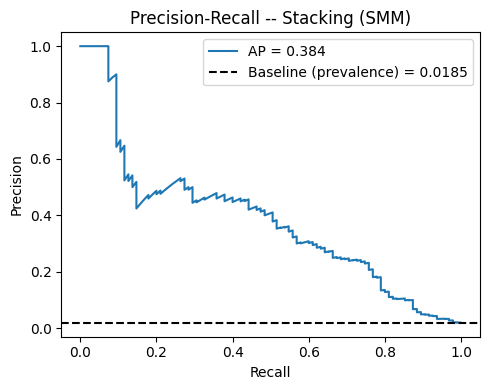

In [129]:
auc_stack = plot_roc(y_test, y_proba_stack, "Stacking (SMM)", "Fig_ROC_Stacking_SMM")
ap_stack  = plot_pr(y_test, y_proba_stack, "Stacking (SMM)", "Fig_PR_Stacking_SMM")

                   Modelo      AUC  Average Precision
           Stacking (SMM) 0.913370           0.384152
      Random Forest (SMM) 0.899594           0.360298
            XGBoost (SMM) 0.909312           0.358302
Logistic Regression (SMM) 0.889030           0.338908
        Extra Trees (SMM) 0.899581           0.314996


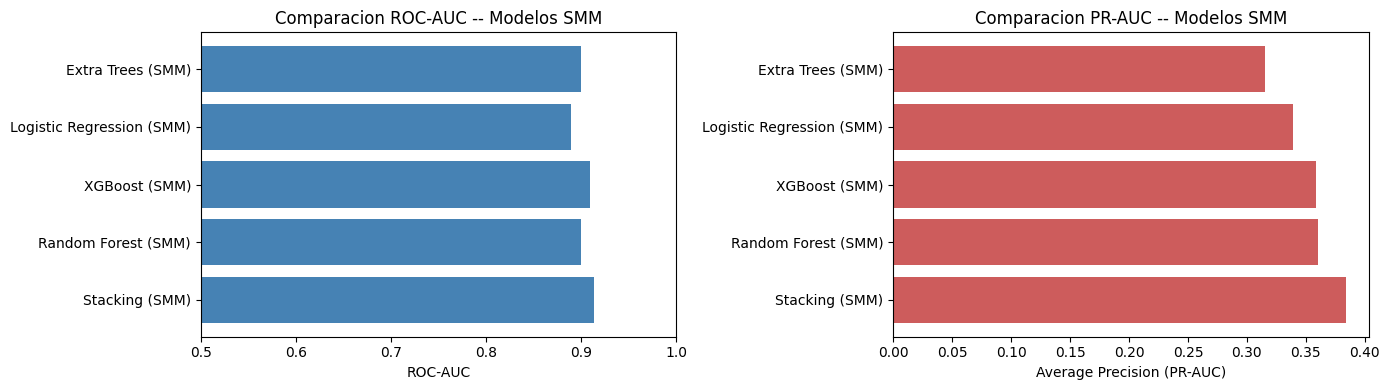

In [130]:
results = pd.DataFrame([
    {"Modelo": "Random Forest (SMM)",       "AUC": auc_rf,    "Average Precision": ap_rf},
    {"Modelo": "XGBoost (SMM)",              "AUC": auc_xgb,   "Average Precision": ap_xgb},
    {"Modelo": "Extra Trees (SMM)",          "AUC": auc_et,    "Average Precision": ap_et},
    {"Modelo": "Logistic Regression (SMM)",  "AUC": auc_rl,    "Average Precision": ap_rl},
    {"Modelo": "Stacking (SMM)",              "AUC": auc_stack, "Average Precision": ap_stack},
]).sort_values("Average Precision", ascending=False)

print(results.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14,4))
axes[0].barh(results["Modelo"], results["AUC"], color="steelblue")
axes[0].set_xlabel("ROC-AUC"); axes[0].set_xlim(0.5, 1.0)
axes[0].set_title("Comparacion ROC-AUC -- Modelos SMM")

axes[1].barh(results["Modelo"], results["Average Precision"], color="indianred")
axes[1].set_xlabel("Average Precision (PR-AUC)")
axes[1].set_title("Comparacion PR-AUC -- Modelos SMM")

plt.tight_layout()
plt.show()

#### **12.6. Sensitivity check: restricting to the official denominator (delivery hospitalizations)**

The model was trained on the full expanded obstetric cohort (Section 2.5). Here we recompute the best
model's (`stacking_clf`) metrics **restricting the test set** to rows where
`is_delivery_hospitalization == 1` -- the denominator comparable 1:1 with rates published by CDC/Nebraska
DHHS (58-88 per 10,000 deliveries). This does not retrain the model, it only evaluates its performance on
the officially comparable subset, as a cross-check of the two paths represented in Section 2.


In [131]:
# Delivery flag comes from df_delivery_ref (it is no longer a model feature); index-aligned with X_test.
parto_mask_test = (df_delivery_ref.loc[X_test.index, "is_delivery_hospitalization"] == 1)

if parto_mask_test.sum() > 0:
    X_test_parto = X_test[parto_mask_test]
    y_test_parto = y_test[parto_mask_test]
    y_pred_parto  = stacking_clf.predict(X_test_parto)
    y_proba_parto = stacking_clf.predict_proba(X_test_parto)[:, 1]

    print(f"N in delivery subset (test): {len(y_test_parto)}  |  "
          f"SMM positives: {y_test_parto.sum()} ({y_test_parto.mean()*100:.3f}%)")
    print("CDC/Nebraska DHHS reference: 0.58%-0.88%\n")

    print(classification_report(y_test_parto, y_pred_parto))

    ap_parto = average_precision_score(y_test_parto, y_proba_parto)
    print(f"Average Precision (delivery subset): {ap_parto:.3f}  "
          f"(vs. {ap_stack:.3f} on the full expanded cohort)")
else:
    print("No delivery hospitalizations in the test set -- review the dataset assembly.")


N in delivery subset (test): 1802  |  SMM positives: 58 (3.219%)
CDC/Nebraska DHHS reference: 0.58%-0.88%

              precision    recall  f1-score   support

           0       0.99      0.93      0.96      1744
           1       0.27      0.78      0.40        58

    accuracy                           0.93      1802
   macro avg       0.63      0.85      0.68      1802
weighted avg       0.97      0.93      0.94      1802

Average Precision (delivery subset): 0.646  (vs. 0.384 on the full expanded cohort)


#### **12.7. Stratified K-Fold Cross-Validation -- Modelo B (mirrors Section 12.6 of Modelo A)**

Section 11 designated stratified K-fold as the primary evidence, but only the single 80/20 split had been
evaluated so far. This section applies the **same protocol as Modelo A (Section 12.6)**: the five already-tuned models are
cloned and re-fit on each of the `N_SPLITS` stratified folds of the **full** `X`/`y` (475 positives, ~95 per fold), and
metrics are reported as mean +/- SD. It makes the A-vs-B comparison symmetric. Caveat (same as in A): the hyperparameters were
selected on the training split, so these estimates can be slightly optimistic.

**Runtime**: expensive (Stacking retrains four base learners + meta-learner per fold). `N_JOBS_CV = 2` is deliberate -- it avoids
the joblib `MemoryError` seen with Modelo A.

In [132]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

# Deliberately NOT n_jobs=-1: nested joblib/loky workers caused a MemoryError (PicklingError) on this
# machine when running Model A. Raise it only if RAM allows.
N_JOBS_CV = 2

def run_cv_safe(model, X_data, y_data, label, verbose=True):
    """Same metrics as run_cv_diagnostics (Section 11), but with a conservative n_jobs."""
    scores = cross_validate(model, X_data, y_data, cv=skf, scoring=cv_scoring, n_jobs=N_JOBS_CV)
    summary = {metric: (np.mean(scores[f"test_{metric}"]), np.std(scores[f"test_{metric}"]))
               for metric in cv_scoring}
    if verbose:
        print(f"--- {label} ({N_SPLITS}-fold Stratified CV) ---")
        for metric, (m, s) in summary.items():
            print(f"  {metric:20s}: {m:.3f} +/- {s:.3f}")
    return summary

def summaries_to_table(summaries):
    rows = []
    for name, summary in summaries.items():
        row = {"Model": name}
        for metric, (m, s) in summary.items():
            row[metric] = f"{m:.3f} +/- {s:.3f}"
        rows.append(row)
    return pd.DataFrame(rows).set_index("Model")

In [133]:
final_models = {
    "Random Forest (SMM)":        best_model_rf,
    "XGBoost (SMM)":              best_model_xgb,
    "Extra Trees (SMM)":          best_model_et,
    "Logistic Regression (SMM)":  best_model_rl,
    "Stacking (SMM)":             stacking_clf,
}

# Full X/y (Section 10, pre-split), clone() drops each model's fitted state, so every fold refits from
# scratch on its own training portion with the hyperparameters GridSearchCV already selected.
cv_summaries = {}
for name, fitted_model in final_models.items():
    cv_summaries[name] = run_cv_safe(
        clone(fitted_model), X, y, f"{name} -- tuned, {N_SPLITS}-fold CV on full X/y"
    )

--- Random Forest (SMM) -- tuned, 5-fold CV on full X/y (5-fold Stratified CV) ---
  roc_auc             : 0.890 +/- 0.028
  average_precision   : 0.368 +/- 0.037
  recall              : 0.467 +/- 0.034
  f1                  : 0.444 +/- 0.032
  balanced_accuracy   : 0.728 +/- 0.017
--- XGBoost (SMM) -- tuned, 5-fold CV on full X/y (5-fold Stratified CV) ---
  roc_auc             : 0.901 +/- 0.017
  average_precision   : 0.413 +/- 0.038
  recall              : 0.758 +/- 0.040
  f1                  : 0.264 +/- 0.011
  balanced_accuracy   : 0.841 +/- 0.019
--- Extra Trees (SMM) -- tuned, 5-fold CV on full X/y (5-fold Stratified CV) ---
  roc_auc             : 0.885 +/- 0.023
  average_precision   : 0.359 +/- 0.042
  recall              : 0.560 +/- 0.041
  f1                  : 0.362 +/- 0.035
  balanced_accuracy   : 0.766 +/- 0.021
--- Logistic Regression (SMM) -- tuned, 5-fold CV on full X/y (5-fold Stratified CV) ---
  roc_auc             : 0.876 +/- 0.029
  average_precision   : 0.342 

,roc_auc,average_precision,recall,f1,balanced_accuracy
Model,,,,,
Random Forest (SMM),0.890 +/- 0.028,0.368 +/- 0.037,0.467 +/- 0.034,0.444 +/- 0.032,0.728 +/- 0.017
XGBoost (SMM),0.901 +/- 0.017,0.413 +/- 0.038,0.758 +/- 0.040,0.264 +/- 0.011,0.841 +/- 0.019
Extra Trees (SMM),0.885 +/- 0.023,0.359 +/- 0.042,0.560 +/- 0.041,0.362 +/- 0.035,0.766 +/- 0.021
Logistic Regression (SMM),0.876 +/- 0.029,0.342 +/- 0.048,0.749 +/- 0.074,0.233 +/- 0.018,0.831 +/- 0.036
Stacking (SMM),0.904 +/- 0.020,0.419 +/- 0.050,0.800 +/- 0.040,0.234 +/- 0.013,0.852 +/- 0.018


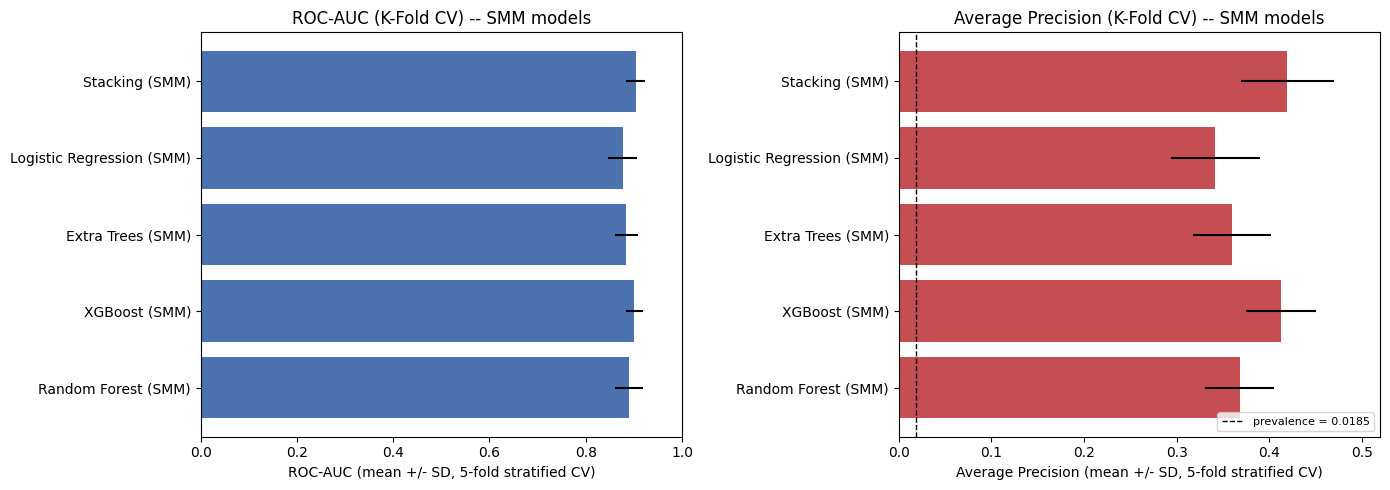

In [134]:
cv_table_df = summaries_to_table(cv_summaries)
display(cv_table_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
model_names = list(cv_summaries.keys())
auc_means = [cv_summaries[m]["roc_auc"][0] for m in model_names]
auc_stds  = [cv_summaries[m]["roc_auc"][1] for m in model_names]
ap_means  = [cv_summaries[m]["average_precision"][0] for m in model_names]
ap_stds   = [cv_summaries[m]["average_precision"][1] for m in model_names]
prevalence = float(np.mean(y))

axes[0].barh(model_names, auc_means, xerr=auc_stds, color="#4C72B0")
axes[0].set_xlim(0.0, 1.0)
axes[0].set_xlabel("ROC-AUC (mean +/- SD, 5-fold stratified CV)")
axes[0].set_title("ROC-AUC (K-Fold CV) -- SMM models")

axes[1].barh(model_names, ap_means, xerr=ap_stds, color="#C44E52")
axes[1].axvline(prevalence, color="k", linestyle="--", linewidth=1, label=f"prevalence = {prevalence:.4f}")
axes[1].set_xlim(0.0, max(ap_means) + max(ap_stds) + 0.05)
axes[1].set_xlabel("Average Precision (mean +/- SD, 5-fold stratified CV)")
axes[1].set_title("Average Precision (K-Fold CV) -- SMM models")
axes[1].legend(loc="lower right", fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Fig_CV_Comparison_SMM.pdf"), format="pdf", bbox_inches="tight")
plt.savefig(os.path.join(FIG_DIR, "Fig_CV_Comparison_SMM.png"), format="png", dpi=300, bbox_inches="tight")
plt.show()

#### **12.8. Oversampling (SMOTE) -- Sensitivity Analysis for Modelo B**

Same design as Section 12.7 of Modelo A: `SMOTE(sampling_strategy=0.2, k_neighbors=5)` **inside** each training fold through an
`imblearn` pipeline (never before the split), compared against the class-weighting results of Section 12.7. With 475 real positives
(~380 per training fold) SMOTE has much more to interpolate from than in Modelo A, so this is a fairer test. It is a **sensitivity analysis**, not a
replacement of class weighting; read large jumps with suspicion.

**Runtime**: the slowest cell of the notebook (SMOTE + stacking, `N_SPLITS` times). Set `RUN_SMOTE_B = False` to skip it.

In [135]:
RUN_SMOTE_B = True

if RUN_SMOTE_B:
    # Same partial-rebalancing pipeline as Modelo A (Section 12.7 there), applied INSIDE each CV fold only.
    SMOTE_SAMPLING_STRATEGY = 0.2
    SMOTE_K_NEIGHBORS = 5

    def make_smote_pipeline(fitted_model):
        return ImbPipeline([
            ("smote", SMOTE(sampling_strategy=SMOTE_SAMPLING_STRATEGY,
                            k_neighbors=SMOTE_K_NEIGHBORS, random_state=42)),
            ("clf", clone(fitted_model)),
        ])

    cv_summaries_smote = {}
    for name, fitted_model in final_models.items():
        cv_summaries_smote[name] = run_cv_safe(
            make_smote_pipeline(fitted_model), X, y,
            f"{name} + SMOTE (sampling_strategy={SMOTE_SAMPLING_STRATEGY})"
        )

--- Random Forest (SMM) + SMOTE (sampling_strategy=0.2) (5-fold Stratified CV) ---
  roc_auc             : 0.899 +/- 0.026
  average_precision   : 0.366 +/- 0.051
  recall              : 0.539 +/- 0.042
  f1                  : 0.406 +/- 0.031
  balanced_accuracy   : 0.759 +/- 0.021
--- XGBoost (SMM) + SMOTE (sampling_strategy=0.2) (5-fold Stratified CV) ---
  roc_auc             : 0.892 +/- 0.027
  average_precision   : 0.350 +/- 0.068
  recall              : 0.964 +/- 0.031
  f1                  : 0.047 +/- 0.001
  balanced_accuracy   : 0.618 +/- 0.011
--- Extra Trees (SMM) + SMOTE (sampling_strategy=0.2) (5-fold Stratified CV) ---
  roc_auc             : 0.875 +/- 0.027
  average_precision   : 0.349 +/- 0.039
  recall              : 0.535 +/- 0.036
  f1                  : 0.428 +/- 0.029
  balanced_accuracy   : 0.758 +/- 0.018
--- Logistic Regression (SMM) + SMOTE (sampling_strategy=0.2) (5-fold Stratified CV) ---
  roc_auc             : 0.825 +/- 0.045
  average_precision   : 0.357 

,roc_auc (class weights),roc_auc (SMOTE),average_precision (class weights),average_precision (SMOTE),recall (class weights),recall (SMOTE),f1 (class weights),f1 (SMOTE),balanced_accuracy (class weights),balanced_accuracy (SMOTE)
Model,,,,,,,,,,
Random Forest (SMM),0.890 +/- 0.028,0.899 +/- 0.026,0.368 +/- 0.037,0.366 +/- 0.051,0.467 +/- 0.034,0.539 +/- 0.042,0.444 +/- 0.032,0.406 +/- 0.031,0.728 +/- 0.017,0.759 +/- 0.021
XGBoost (SMM),0.901 +/- 0.017,0.892 +/- 0.027,0.413 +/- 0.038,0.350 +/- 0.068,0.758 +/- 0.040,0.964 +/- 0.031,0.264 +/- 0.011,0.047 +/- 0.001,0.841 +/- 0.019,0.618 +/- 0.011
Extra Trees (SMM),0.885 +/- 0.023,0.875 +/- 0.027,0.359 +/- 0.042,0.349 +/- 0.039,0.560 +/- 0.041,0.535 +/- 0.036,0.362 +/- 0.035,0.428 +/- 0.029,0.766 +/- 0.021,0.758 +/- 0.018
Logistic Regression (SMM),0.876 +/- 0.029,0.825 +/- 0.045,0.342 +/- 0.048,0.357 +/- 0.062,0.749 +/- 0.074,0.554 +/- 0.040,0.233 +/- 0.018,0.388 +/- 0.029,0.831 +/- 0.036,0.765 +/- 0.020
Stacking (SMM),0.904 +/- 0.020,0.896 +/- 0.029,0.419 +/- 0.050,0.406 +/- 0.056,0.800 +/- 0.040,0.636 +/- 0.048,0.234 +/- 0.013,0.382 +/- 0.027,0.852 +/- 0.018,0.802 +/- 0.024


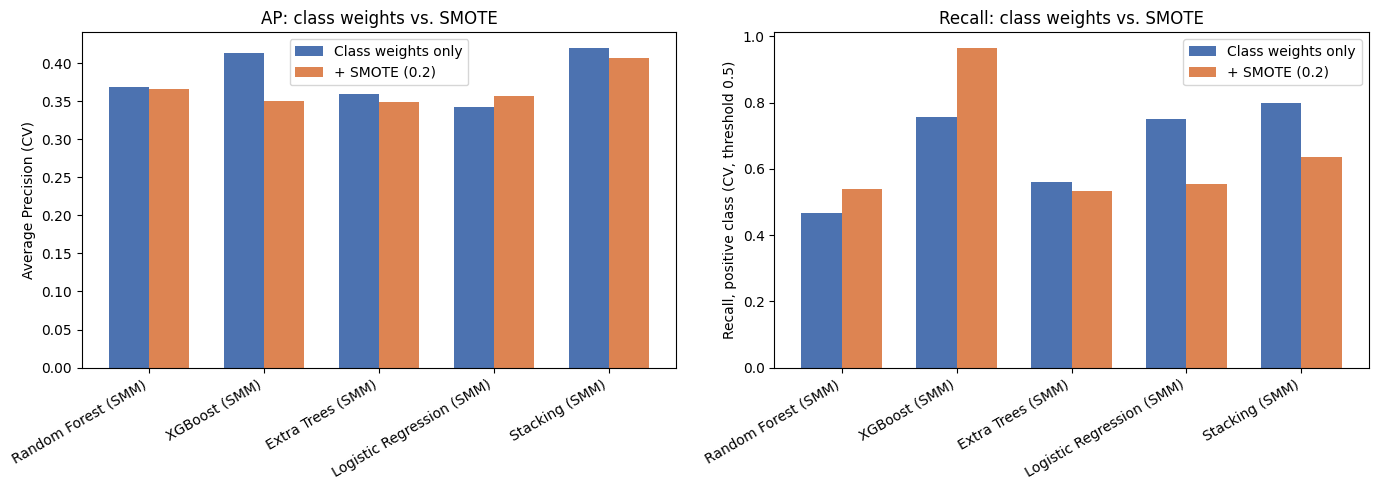

In [136]:
if RUN_SMOTE_B:
    comparison_rows = []
    for name in final_models:
        row = {"Model": name}
        for metric in ["roc_auc", "average_precision", "recall", "f1", "balanced_accuracy"]:
            m_base, s_base = cv_summaries[name][metric]
            m_smote, s_smote = cv_summaries_smote[name][metric]
            row[f"{metric} (class weights)"] = f"{m_base:.3f} +/- {s_base:.3f}"
            row[f"{metric} (SMOTE)"] = f"{m_smote:.3f} +/- {s_smote:.3f}"
        comparison_rows.append(row)
    comparison_df = pd.DataFrame(comparison_rows).set_index("Model")
    display(comparison_df)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    x = np.arange(len(final_models)); width = 0.35
    model_names = list(final_models.keys())
    ap_base      = [cv_summaries[m]["average_precision"][0] for m in model_names]
    ap_smote     = [cv_summaries_smote[m]["average_precision"][0] for m in model_names]
    recall_base  = [cv_summaries[m]["recall"][0] for m in model_names]
    recall_smote = [cv_summaries_smote[m]["recall"][0] for m in model_names]

    axes[0].bar(x - width/2, ap_base,  width, label="Class weights only", color="#4C72B0")
    axes[0].bar(x + width/2, ap_smote, width, label="+ SMOTE (0.2)", color="#DD8452")
    axes[0].set_xticks(x); axes[0].set_xticklabels(model_names, rotation=30, ha="right")
    axes[0].set_ylabel("Average Precision (CV)"); axes[0].set_title("AP: class weights vs. SMOTE"); axes[0].legend()

    axes[1].bar(x - width/2, recall_base,  width, label="Class weights only", color="#4C72B0")
    axes[1].bar(x + width/2, recall_smote, width, label="+ SMOTE (0.2)", color="#DD8452")
    axes[1].set_xticks(x); axes[1].set_xticklabels(model_names, rotation=30, ha="right")
    axes[1].set_ylabel("Recall, positive class (CV, threshold 0.5)"); axes[1].set_title("Recall: class weights vs. SMOTE"); axes[1].legend()

    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "Fig_SMOTE_Comparison_SMM.pdf"), format="pdf", bbox_inches="tight")
    plt.savefig(os.path.join(FIG_DIR, "Fig_SMOTE_Comparison_SMM.png"), format="png", dpi=300, bbox_inches="tight")
    plt.show()

#### **12.9. Subgroup performance audit (equity check) -- Modelo B**

Hold-out performance of the stacked model by **ethnicity group, insurance, age quartile, ICU stay and delivery vs. non-delivery** admission
(groups are read from the one-hot columns of `X_test`; the delivery flag from `df_delivery_ref`). AUC/AP are reported only when a subgroup has at least
`MIN_POS = 10` positives **and** 10 negatives (95% bootstrap CI for the AUC); smaller groups only show their counts and the default-threshold
recall/precision. Differences between subgroups are **descriptive**: with this sample size the CIs are wide and no formal fairness
claim is possible. Modelo A is not audited because 8 test positives cannot support subgroup estimates.

n  positives  prevalence  \
dimension       group                                               
Ethnicity group AFRO_DESC             1285         28       0.022   
                ASIAN                  437          3       0.007   
                HISPANIC               531          5       0.009   
                INDIAN_USA              27          1       0.037   
                PACIFIC_ISL              8          0       0.000   
                UNKNOWN                619         17       0.027   
                WHITE_UE               149          2       0.013   
                WHITE_USA             2092         39       0.019   
Insurance       (reference category)    38          0       0.000   
                MEDICAID              1731         32       0.018   
                MEDICARE                67          1       0.015   
                OTHERS                 118          2       0.017   
                PRIVATE               3194         60       0.019   
Age quartile    (-0.001, 0.27]        1312         20       0.015   
                (0.27, 0.378]         1271         18       0.014   
                (0.378, 0.486]        1333         29       0.022   
                (0.486, 0.946]        1232         28       0.023   
ICU stay        ICU stay                94         36       0.383   
                No ICU stay           5054         59       0.012   
Delivery hosp.  Delivery              1802         58       0.032   
                Non-delivery          3346         37       0.011   

                                      flagged (pred=1)    AUC  \
dimension       group                                           
Ethnicity group AFRO_DESC                        0.121  0.866   
                ASIAN                            0.059    NaN   
                HISPANIC                         0.079    NaN   
                INDIAN_USA                       0.074    NaN   
                PACIFIC_ISL                      0.000    NaN   
                UNKNOWN                          0.124  0.944   
                WHITE_UE                         0.081    NaN   
                WHITE_USA                        0.112  0.921   
Insurance       (reference category)             0.105    NaN   
                MEDICAID                         0.104  0.902   
                MEDICARE                         0.403    NaN   
                OTHERS                           0.093    NaN   
                PRIVATE                          0.102  0.923   
Age quartile    (-0.001, 0.27]                   0.089  0.884   
                (0.27, 0.378]                    0.098  0.940   
                (0.378, 0.486]                   0.110  0.953   
                (0.486, 0.946]                   0.131  0.860   
ICU stay        ICU stay                         0.989  0.655   
                No ICU stay                      0.090  0.873   
Delivery hosp.  Delivery                         0.092  0.920   
                Non-delivery                     0.114  0.913   

                                               AUC 95% CI     AP  recall@0.5  \
dimension       group                                                          
Ethnicity group AFRO_DESC                  [0.769, 0.946]  0.304       0.714   
                ASIAN                 n/a (<10 positives)    NaN       0.667   
                HISPANIC              n/a (<10 positives)    NaN       1.000   
                INDIAN_USA            n/a (<10 positives)    NaN       1.000   
                PACIFIC_ISL           n/a (<10 positives)    NaN         NaN   
                UNKNOWN                    [0.865, 0.984]  0.532       0.882   
                WHITE_UE              n/a (<10 positives)    NaN       0.500   
                WHITE_USA                  [0.868, 0.965]  0.355       0.795   
Insurance       (reference category)  n/a (<10 positives)    NaN         NaN   
                MEDICAID                   [0.820, 0.967]  0.430       0.844 


AUC gap between subgroups with >= 10 positives (max - min), by dimension:
  Ethnicity group   : 0.077  (UNKNOWN vs AFRO_DESC)
  Insurance         : 0.022  (PRIVATE vs MEDICAID)
  Age quartile      : 0.093  ((0.378, 0.486] vs (0.486, 0.946])
  ICU stay          : 0.218  (No ICU stay vs ICU stay)
  Delivery hosp.    : 0.007  (Delivery vs Non-delivery)


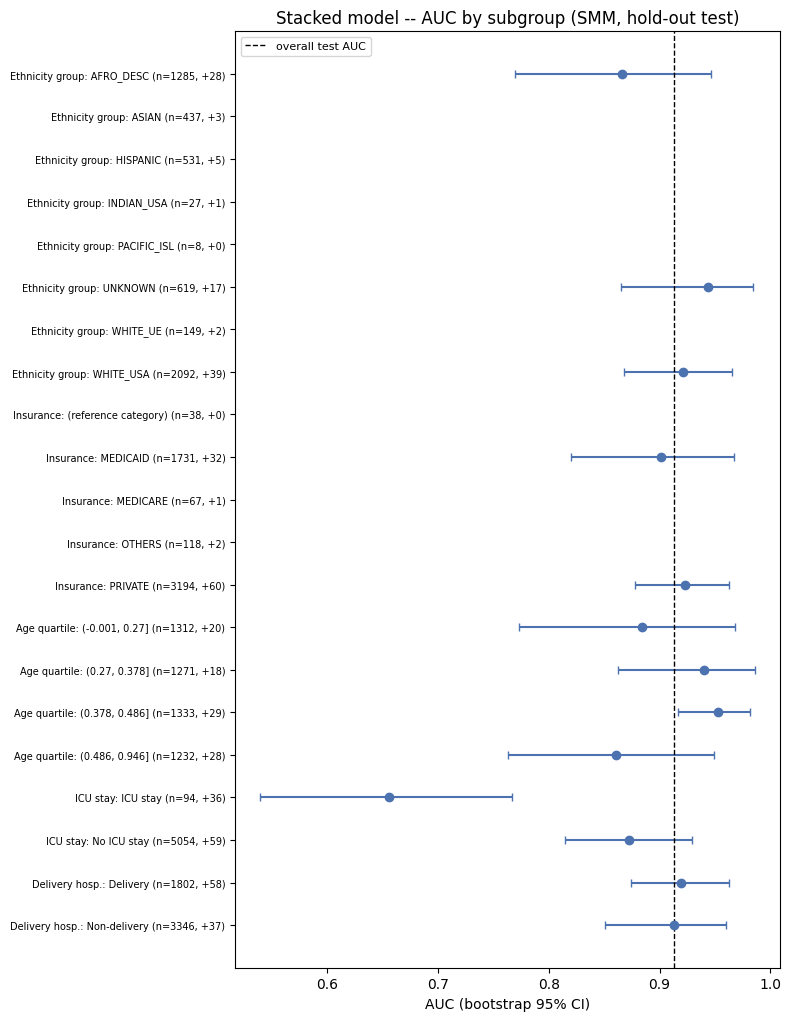

In [137]:
N_BOOT_SG = 500
MIN_POS = 10     # below this many positives, AUC/AP are not reported (too unstable)

y_prob_te = stacking_clf.predict_proba(X_test)[:, 1]
y_pred_te = stacking_clf.predict(X_test)
y_te = np.asarray(y_test)

def _onehot_to_label(Xdf, prefix):
    cols = [c for c in Xdf.columns if c.startswith(prefix)]
    dummies = Xdf[cols].astype(int)
    lab = dummies.idxmax(axis=1).str.replace(prefix, "", regex=False)
    lab[dummies.sum(axis=1) == 0] = "(reference category)"
    return lab

age_q = pd.qcut(X_test["age_at_admission_scaled"], 4, duplicates="drop")
subgroup_defs = {
    "Ethnicity group": _onehot_to_label(X_test, "ethnicity_group_"),
    "Insurance":       _onehot_to_label(X_test, "insurance_"),
    "Age quartile":    age_q.astype(str),
    "ICU stay":        X_test["icu_stay"].astype(int).map({0: "No ICU stay", 1: "ICU stay"}),
    "Delivery hosp.":  df_delivery_ref.loc[X_test.index, "is_delivery_hospitalization"].map({1: "Delivery", 0: "Non-delivery"}),
}

def _auc_ci(yt, yp, n_boot=N_BOOT_SG, seed=42):
    rng = np.random.default_rng(seed); n = len(yt); vals = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        if yt[i].sum() in (0, n):
            continue
        vals.append(roc_auc_score(yt[i], yp[i]))
    return np.percentile(vals, [2.5, 97.5])

rows = []
for dim, labels in subgroup_defs.items():
    labels = pd.Series(np.asarray(labels), index=X_test.index).fillna("(missing)")
    for g in sorted(labels.unique()):
        m = (labels == g).values
        yt, yp, yd = y_te[m], y_prob_te[m], y_pred_te[m]
        pos = int(yt.sum()); row = {"dimension": dim, "group": g, "n": int(m.sum()), "positives": pos,
                                    "prevalence": yt.mean(), "flagged (pred=1)": yd.mean()}
        if pos >= MIN_POS and (len(yt) - pos) >= MIN_POS:
            lo, hi = _auc_ci(yt, yp)
            row.update({"AUC": roc_auc_score(yt, yp), "AUC 95% CI": f"[{lo:.3f}, {hi:.3f}]",
                        "AP": average_precision_score(yt, yp), "recall@0.5": recall_score(yt, yd),
                        "precision@0.5": precision_score(yt, yd, zero_division=0)})
        else:
            row.update({"AUC": np.nan, "AUC 95% CI": "n/a (<%d positives)" % MIN_POS, "AP": np.nan,
                        "recall@0.5": (recall_score(yt, yd) if pos > 0 else np.nan),
                        "precision@0.5": (precision_score(yt, yd, zero_division=0) if pos > 0 else np.nan)})
        rows.append(row)

subgroup_df = pd.DataFrame(rows).set_index(["dimension", "group"])
display(subgroup_df.round(3))
subgroup_df.to_csv(os.path.join(DATA_DIR, "Table_Subgroup_Performance_SMM.csv"))

print("\nAUC gap between subgroups with >= %d positives (max - min), by dimension:" % MIN_POS)
for dim in subgroup_defs:
    a = subgroup_df.loc[dim, "AUC"].dropna()
    print(f"  {dim:18s}: " + (f"{a.max() - a.min():.3f}  ({a.idxmax()} vs {a.idxmin()})" if len(a) >= 2 else "not enough groups"))

fig, ax = plt.subplots(figsize=(8, 0.42 * len(subgroup_df) + 1.5))
ypos = 0; yticks = []; ylabels = []
for (dim, g), r in subgroup_df.iterrows():
    if not np.isnan(r["AUC"]):
        lo, hi = [float(v) for v in r["AUC 95% CI"].strip("[]").split(",")]
        ax.errorbar(r["AUC"], ypos, xerr=[[r["AUC"] - lo], [hi - r["AUC"]]], fmt="o", color="#4C72B0", capsize=3)
    yticks.append(ypos); ylabels.append(f"{dim}: {g} (n={r['n']}, +{r['positives']})"); ypos -= 1
ax.axvline(roc_auc_score(y_te, y_prob_te), color="k", linestyle="--", linewidth=1, label="overall test AUC")
ax.set_yticks(yticks); ax.set_yticklabels(ylabels, fontsize=7); ax.set_xlabel("AUC (bootstrap 95% CI)")
ax.set_title("Stacked model -- AUC by subgroup (SMM, hold-out test)"); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Fig_Subgroup_AUC_SMM.pdf"), format="pdf", bbox_inches="tight")
plt.savefig(os.path.join(FIG_DIR, "Fig_Subgroup_AUC_SMM.png"), format="png", dpi=300, bbox_inches="tight")
plt.show()

### **13. Explainability (SHAP)**

As in Modelo A, this is left commented out until there is a real run against the database. With a
number of positive cases orders of magnitude larger than Modelo A, the SHAP attributions here rest on a
considerably more solid statistical basis -- they should still be interpreted as descriptive of the
fitted model's behaviour, not as causal evidence.


In [138]:
explainer        = shap.TreeExplainer(stacking_clf.named_estimators_['rf'])
shap_explanation = explainer(X_test)
shap_plot        = shap_explanation[:, :, 1]   # 3D -> clase "SMM"

plt.figure(figsize=(9, 6))
shap.plots.beeswarm(shap_plot, max_display=15, show=False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Fig_SHAP_RF_SMM.pdf"), dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(FIG_DIR, "Fig_SHAP_RF_SMM.png"), dpi=300, bbox_inches='tight')
plt.close()
print("Listo RF")

Listo RF


In [139]:
explainer        = shap.TreeExplainer(stacking_clf.named_estimators_['xgb'])
shap_explanation = explainer(X_test)
shap_plot        = shap_explanation   # XGB devuelve 2D directo

plt.figure(figsize=(9, 6))
shap.plots.beeswarm(shap_plot, max_display=15, show=False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Fig_SHAP_XGBoost_SMM.pdf"), dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(FIG_DIR, "Fig_SHAP_XGBoost_SMM.png"), dpi=300, bbox_inches='tight')
plt.close()
print("Listo XGB")

Listo XGB


In [140]:
explainer        = shap.TreeExplainer(stacking_clf.named_estimators_['et'])
shap_explanation = explainer(X_test, check_additivity=False)
shap_plot        = shap_explanation[:, :, 1]

plt.figure(figsize=(9, 6))
shap.plots.beeswarm(shap_plot, max_display=15, show=False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Fig_SHAP_Extra_Trees_SMM.pdf"), dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(FIG_DIR, "Fig_SHAP_Extra_Trees_SMM.png"), dpi=300, bbox_inches='tight')
plt.close()
print("Listo ET")

Listo ET


In [141]:
explainer     = shap.LinearExplainer(stacking_clf.named_estimators_['rl'], X_train)
shap_vals_raw = explainer.shap_values(X_test)

if isinstance(shap_vals_raw, list):
    shap_vals = shap_vals_raw[1]
else:
    shap_vals = shap_vals_raw

shap_vals = np.array(shap_vals, dtype=np.float64)
X_test_np = X_test.astype(np.float64)

plt.figure(figsize=(9, 6))
shap.summary_plot(shap_vals, X_test_np, max_display=15, show=False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Fig_SHAP_Logistic_Reg_SMM.pdf"), dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(FIG_DIR, "Fig_SHAP_Logistic_Reg_SMM.png"), dpi=300, bbox_inches='tight')
plt.close()
print("Listo LR")

Listo LR


#### **13.1. SHAP for the XGBoost base learner (executed)**

The commented cells above remain as templates. This cell computes SHAP values (TreeSHAP) of the **fitted XGBoost base learner inside the stacking model**
on the 5,148 test admissions and plots the 15 most influential predictors (beeswarm and mean |SHAP|). With 475 positives the attributions are more
credible than in Modelo A, but they remain **descriptive of the fitted model**, not causal. Note that SHAP values are in log-odds units of a model trained with class
weights. If `shap` and `xgboost` disagree on version, the cell falls back to XGBoost's own TreeSHAP (`pred_contribs=True`).

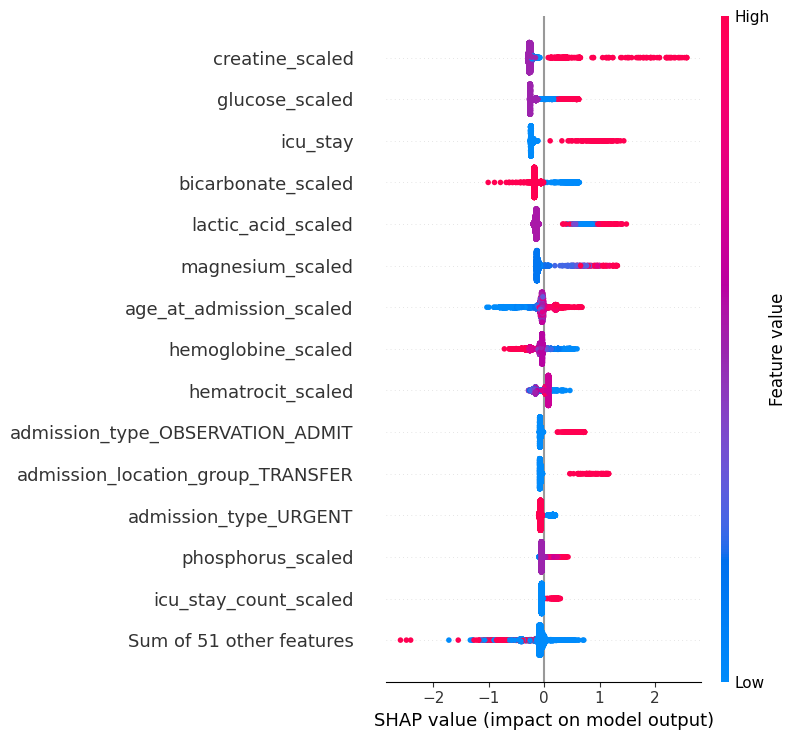

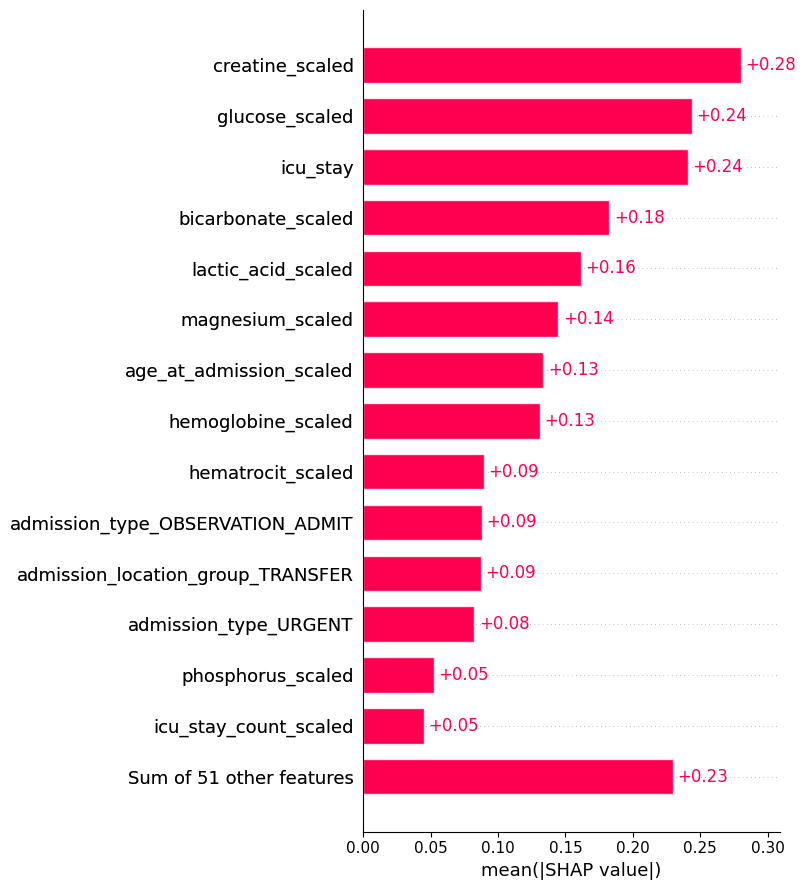

,mean |SHAP| (log-odds)
creatine_scaled,0.280431
glucose_scaled,0.244058
icu_stay,0.240932
bicarbonate_scaled,0.182587
lactic_acid_scaled,0.161438
magnesium_scaled,0.144808
age_at_admission_scaled,0.133655
hemoglobine_scaled,0.131322
hematrocit_scaled,0.089546
admission_type_OBSERVATION_ADMIT,0.087770


In [142]:
import shap

# Descriptive attribution of the fitted XGBoost base learner (the stacking meta-learner is not explained).
xgb_fitted = stacking_clf.named_estimators_["xgb"]
try:
    explainer = shap.TreeExplainer(xgb_fitted)
    shap_explanation = explainer(X_test)
    shap_values = shap_explanation.values
except Exception as exc:      # some shap/xgboost version pairs disagree -> use XGBoost's own TreeSHAP
    print(f"shap.TreeExplainer failed ({type(exc).__name__}: {exc}); falling back to native XGBoost contributions.")
    import xgboost as xgb
    contrib = xgb_fitted.get_booster().predict(xgb.DMatrix(X_test.astype(float)), pred_contribs=True)
    shap_values = contrib[:, :-1]
    shap_explanation = shap.Explanation(values=shap_values, base_values=contrib[:, -1],
                                        data=X_test.astype(float).values, feature_names=list(X_test.columns))

plt.figure(figsize=(9, 6))
shap.plots.beeswarm(shap_explanation, max_display=15, show=False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Fig_SHAP_XGBoost_SMM.pdf"), dpi=300, bbox_inches="tight")
plt.savefig(os.path.join(FIG_DIR, "Fig_SHAP_XGBoost_SMM.png"), dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 5.5))
shap.plots.bar(shap_explanation, max_display=15, show=False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Fig_SHAP_Bar_XGBoost_SMM.pdf"), dpi=300, bbox_inches="tight")
plt.savefig(os.path.join(FIG_DIR, "Fig_SHAP_Bar_XGBoost_SMM.png"), dpi=300, bbox_inches="tight")
plt.show()

mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=X_test.columns).sort_values(ascending=False)
display(mean_abs_shap.head(15).rename("mean |SHAP| (log-odds)").to_frame())

### **14. Risk Stratification Bands -- Adapted for Moderate Imbalance**

With an expected prevalence of ~0.5%-1% (versus ~0.15% in Modelo A), the fixed thresholds used in the
neonatal model (tau_low=0.35, tau_high=0.65) are still not directly applicable (a well-calibrated model
will rarely assign `p_hat > 0.5` to an individual patient when the base rate is ~0.005-0.01),
but the distortion is **less severe** than in Modelo A.

**Recommended approach** (to run once real predictions are available):

1. Use the model's own **predicted-probability distribution** to set relative thresholds
   (e.g. flagging the top 5%-10% of probabilities as "High risk"), instead of fixed absolute
   cutoffs.
2. Report a **sensitivity table** (threshold vs. % of patients flagged vs. recall captured),
   as in Modelo A, but now with bases of tens/hundreds of positive cases -- the resulting curves
   should be notably more stable than Modelo A's.
3. Given the larger N, it **is** reasonable to present a tentative operating point (not just a curve),
   although the final clinical threshold decision must still be referred to a clinical panel -- "This
   decision must be validated by an authorised human responsible party."

```python
# Illustrative code -- run only once stacking_clf, X_test, y_test come from a real model fit.
# y_prob = stacking_clf.predict_proba(X_test)[:, 1]
# y_true = np.array(y_test)
#
# thresholds_to_test = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.65]
# rows = []
# for tau in thresholds_to_test:
#     flagged = y_prob >= tau
#     recall_tau = y_true[flagged].sum() / y_true.sum() if y_true.sum() > 0 else np.nan
#     pct_flagged = flagged.mean()
#     rows.append({"tau": tau, "pct_patients_flagged": pct_flagged, "recall_captured": recall_tau})
# pd.DataFrame(rows)
```


#### **14.1. Implementation -- calibration, "flag the top x%" tables and risk bands**

Implements the recommendations above with actual predictions: (1) **out-of-fold probabilities** over the full cohort (475 events; every admission scored by a stacking model
that did not see it) as the **primary** evidence, with the 80/20 hold-out as secondary; (2) **calibration** (Brier score vs. the prevalence-only reference, mean predicted probability
vs. observed prevalence, reliability plot) -- class-weighted models are expected to over-predict, and this is reported rather than corrected; (3) **top-x% flagged** table
(recall / PPV / lift), **risk bands** from the model's own probability percentiles and **bootstrap 95% CIs**. The operating point is a decision for a clinical panel:
*"This decision must be validated by an authorised human responsible party."*

**Runtime**: one extra stacking CV.

Model B (SMM) -- stacked ensemble -- out-of-fold predictions (full cohort)
N = 25736 | events = 475 | prevalence = 0.01846
Mean predicted probability = 0.24944  (observed prevalence = 0.01846; ratio = 13.5x)
Brier score = 0.09246 | Brier of 'always predict prevalence' = 0.01812 | Brier skill score = -4.104
AUC = 0.902 | AP = 0.396

NOTE: models were trained with class weighting, so raw probabilities are NOT expected to be calibrated to the real prevalence; the RANK-based tables below do not depend on calibration.



,n flagged,true positives,recall,PPV,lift vs prevalence,n flagged per true positive,min probability in flagged
% flagged,,,,,,,
0.5,129,79,0.1663,0.6124,33.1806,1.6329,0.9816
1.0,257,151,0.3179,0.5875,31.8340,1.7020,0.9735
2.0,515,238,0.5011,0.4621,25.0390,2.1639,0.9414
5.0,1287,324,0.6821,0.2517,13.6400,3.9722,0.8036
10.0,2574,372,0.7832,0.1445,7.8304,6.9194,0.5437
20.0,5147,405,0.8526,0.0787,4.2633,12.7086,0.2687


,% flagged,true positives,recall,PPV
tau,,,,
0.05,100.0000,475,1.0000,0.0185
0.10,99.0985,475,1.0000,0.0186
0.20,34.4187,425,0.8947,0.0480
0.30,17.1278,399,0.8400,0.0905
0.50,10.8292,380,0.8000,0.1363
0.65,7.9150,355,0.7474,0.1743
0.80,5.0824,325,0.6842,0.2485


,n,events,event rate,share of all events
band,,,,
Low (<80th pct),20588,70,0.0034,0.1474
Moderate (80-95th pct),3861,81,0.0210,0.1705
High (top 5%),1287,324,0.2517,0.6821


Band cut-offs (probabilities): moderate >= 0.2687, high >= 0.8036

Bootstrap 95% CI (500 resamples): recall@top5%: [0.643, 0.719]; PPV@top5%: [0.226, 0.277]; AUC: [0.884, 0.920]; AP: [0.349, 0.454]


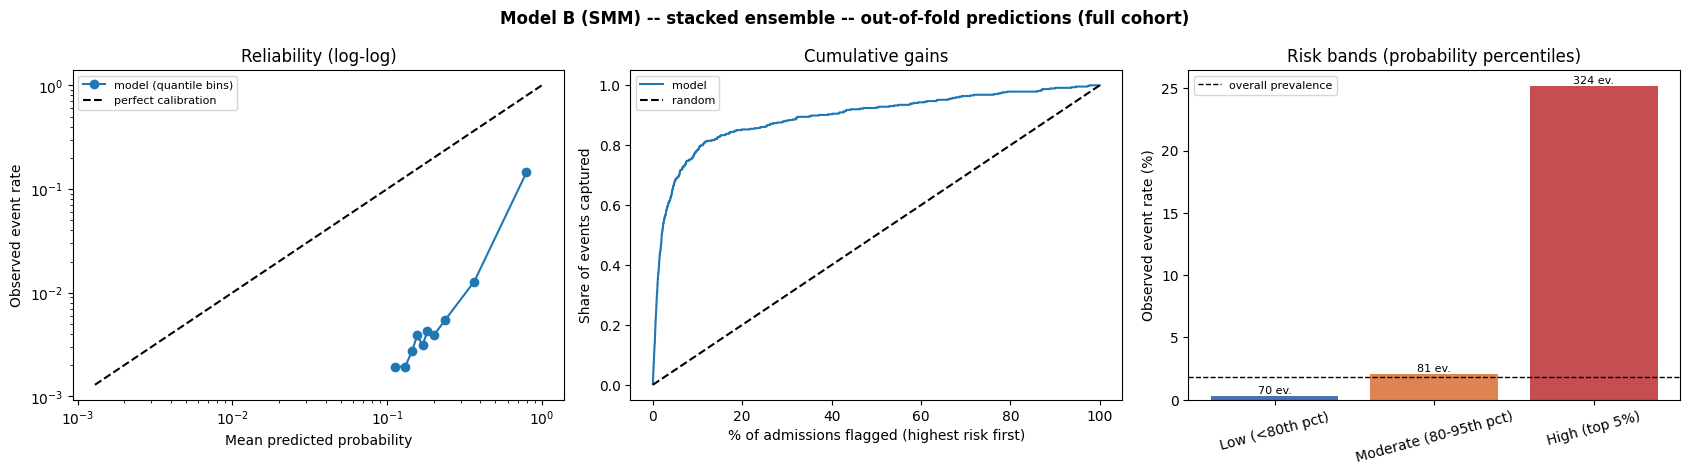

Model B (SMM) -- stacked ensemble -- hold-out test split
N = 5148 | events = 95 | prevalence = 0.01845
Mean predicted probability = 0.25187  (observed prevalence = 0.01845; ratio = 13.6x)
Brier score = 0.09296 | Brier of 'always predict prevalence' = 0.01811 | Brier skill score = -4.132
AUC = 0.913 | AP = 0.384

NOTE: models were trained with class weighting, so raw probabilities are NOT expected to be calibrated to the real prevalence; the RANK-based tables below do not depend on calibration.



,n flagged,true positives,recall,PPV,lift vs prevalence,n flagged per true positive,min probability in flagged
% flagged,,,,,,,
0.5,26,13,0.1368,0.5000,27.0947,2.0000,0.9828
1.0,51,26,0.2737,0.5098,27.6260,1.9615,0.9766
2.0,103,44,0.4632,0.4272,23.1489,2.3409,0.9456
5.0,257,64,0.6737,0.2490,13.4947,4.0156,0.8092
10.0,515,75,0.7895,0.1456,7.8917,6.8667,0.5286
20.0,1030,83,0.8737,0.0806,4.3667,12.4096,0.2701


,% flagged,true positives,recall,PPV
tau,,,,
0.05,100.0000,95,1.0000,0.0185
0.10,99.3201,95,1.0000,0.0186
0.20,38.3061,87,0.9158,0.0441
0.30,17.2883,83,0.8737,0.0933
0.50,10.6449,75,0.7895,0.1369
0.65,7.9837,74,0.7789,0.1800
0.80,5.0894,65,0.6842,0.2481


,n,events,event rate,share of all events
band,,,,
Low (<80th pct),4118,12,0.0029,0.1263
Moderate (80-95th pct),772,19,0.0246,0.2000
High (top 5%),258,64,0.2481,0.6737


Band cut-offs (probabilities): moderate >= 0.2700, high >= 0.8090

Bootstrap 95% CI (500 resamples): recall@top5%: [0.589, 0.780]; PPV@top5%: [0.195, 0.309]; AUC: [0.875, 0.947]; AP: [0.275, 0.484]


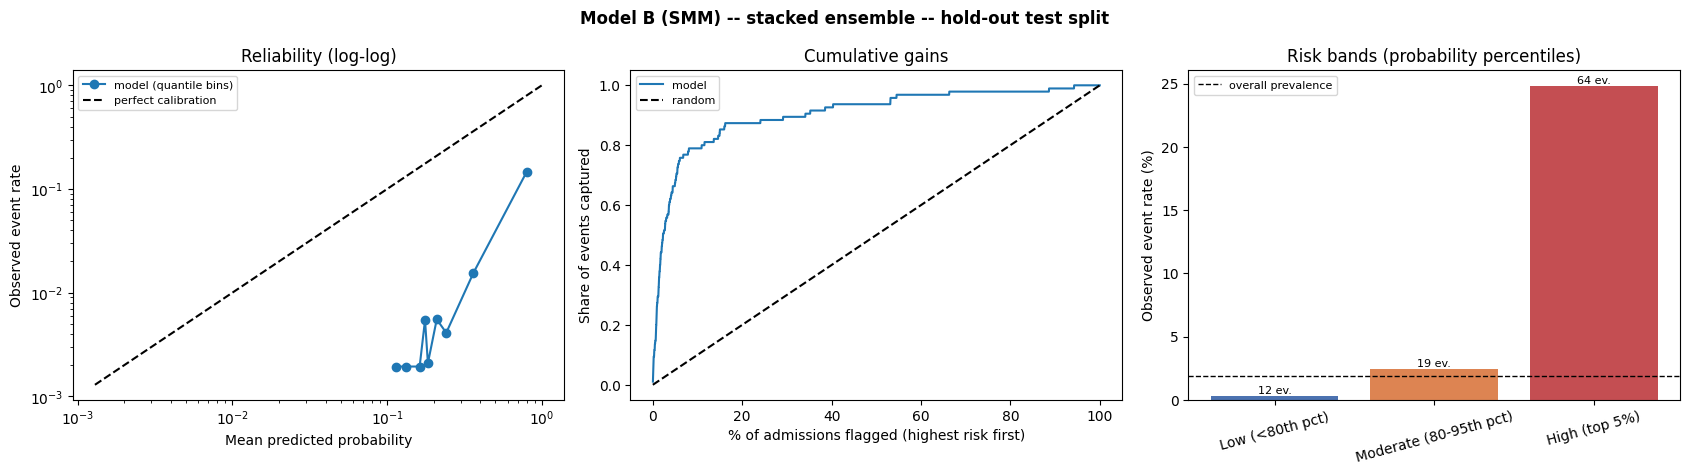

In [143]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

N_JOBS_CV = 2
N_BOOT = 500
LABEL = "SMM"          # used in file names

def _gains_table(y_true, y_prob, pcts=(0.5, 1, 2, 5, 10, 20)):
    """'Flag the top x% highest predicted probabilities' -> recall / PPV / lift. Needs no calibration."""
    y_true = np.asarray(y_true); n = len(y_true); P = y_true.sum(); prev = y_true.mean()
    order = np.argsort(-y_prob)
    rows = []
    for pct in pcts:
        k = max(1, int(round(n * pct / 100)))
        idx = order[:k]; tp = int(y_true[idx].sum())
        rows.append({"% flagged": pct, "n flagged": k, "true positives": tp,
                     "recall": tp / P, "PPV": tp / k, "lift vs prevalence": (tp / k) / prev,
                     "n flagged per true positive": (k / tp) if tp > 0 else np.nan,
                     "min probability in flagged": float(y_prob[idx].min())})
    return pd.DataFrame(rows).set_index("% flagged")

def _absolute_threshold_table(y_true, y_prob, taus=(0.05, 0.10, 0.20, 0.30, 0.50, 0.65, 0.80)):
    y_true = np.asarray(y_true); rows = []
    for tau in taus:
        flagged = y_prob >= tau; k = int(flagged.sum()); tp = int(y_true[flagged].sum())
        rows.append({"tau": tau, "% flagged": 100 * flagged.mean(), "true positives": tp,
                     "recall": tp / y_true.sum(), "PPV": (tp / k) if k > 0 else np.nan})
    return pd.DataFrame(rows).set_index("tau")

def _risk_bands(y_true, y_prob, q_mod=0.80, q_high=0.95):
    """Prevalence-aware bands from the model's OWN probability distribution (not fixed 0.35/0.65 cuts)."""
    y_true = np.asarray(y_true)
    t_mod, t_high = np.quantile(y_prob, [q_mod, q_high])
    band = np.where(y_prob >= t_high, "High (top 5%)", np.where(y_prob >= t_mod, "Moderate (80-95th pct)", "Low (<80th pct)"))
    out = []
    for b in ["Low (<80th pct)", "Moderate (80-95th pct)", "High (top 5%)"]:
        m = band == b
        out.append({"band": b, "n": int(m.sum()), "events": int(y_true[m].sum()),
                    "event rate": y_true[m].mean() if m.sum() else np.nan,
                    "share of all events": y_true[m].sum() / y_true.sum()})
    return pd.DataFrame(out).set_index("band"), (t_mod, t_high)

def _bootstrap_ci(y_true, y_prob, pct=5, n_boot=N_BOOT, seed=42):
    y_true = np.asarray(y_true); n = len(y_true); rng = np.random.default_rng(seed)
    k = max(1, int(round(n * pct / 100))); res = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n); yt = y_true[i]; yp = y_prob[i]
        if yt.sum() == 0 or yt.sum() == n:
            continue
        tp = yt[np.argsort(-yp)[:k]].sum()
        res.append((tp / yt.sum(), tp / k, roc_auc_score(yt, yp), average_precision_score(yt, yp)))
    lo, hi = np.percentile(np.array(res), [2.5, 97.5], axis=0)
    return dict(zip(["recall@top5%", "PPV@top5%", "AUC", "AP"], zip(lo, hi)))

def calibration_and_risk_report(y_true, y_prob, title, fig_suffix, n_bins=10):
    y_true = np.asarray(y_true); prev = y_true.mean()
    brier = brier_score_loss(y_true, y_prob)
    brier_ref = brier_score_loss(y_true, np.full(len(y_true), prev))
    print("=" * 78); print(title); print("=" * 78)
    print(f"N = {len(y_true)} | events = {int(y_true.sum())} | prevalence = {prev:.5f}")
    print(f"Mean predicted probability = {y_prob.mean():.5f}  (observed prevalence = {prev:.5f}; "
          f"ratio = {y_prob.mean() / prev:.1f}x)")
    print(f"Brier score = {brier:.5f} | Brier of 'always predict prevalence' = {brier_ref:.5f} | "
          f"Brier skill score = {1 - brier / brier_ref:.3f}")
    print(f"AUC = {roc_auc_score(y_true, y_prob):.3f} | AP = {average_precision_score(y_true, y_prob):.3f}")
    print("\nNOTE: models were trained with class weighting, so raw probabilities are NOT expected to be "
          "calibrated to the real prevalence; the RANK-based tables below do not depend on calibration.\n")

    gains = _gains_table(y_true, y_prob); display(gains.round(4))
    absolute = _absolute_threshold_table(y_true, y_prob); display(absolute.round(4))
    bands, (t_mod, t_high) = _risk_bands(y_true, y_prob); display(bands.round(4))
    print(f"Band cut-offs (probabilities): moderate >= {t_mod:.4f}, high >= {t_high:.4f}")
    ci = _bootstrap_ci(y_true, y_prob)
    print(f"\nBootstrap 95% CI ({N_BOOT} resamples): " +
          "; ".join(f"{k}: [{lo:.3f}, {hi:.3f}]" for k, (lo, hi) in ci.items()))

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
    frac_pos, mean_pred = calibration_curve(y_true, y_prob, n_bins=n_bins, strategy="quantile")
    ok = (frac_pos > 0) & (mean_pred > 0)
    axes[0].plot(mean_pred[ok], frac_pos[ok], "o-", label="model (quantile bins)")
    lim = [min(mean_pred[ok].min(), frac_pos[ok].min()) / 1.5, 1.0] if ok.any() else [1e-4, 1.0]
    axes[0].plot(lim, lim, "k--", label="perfect calibration")
    axes[0].set_xscale("log"); axes[0].set_yscale("log")
    axes[0].set_xlabel("Mean predicted probability"); axes[0].set_ylabel("Observed event rate")
    axes[0].set_title("Reliability (log-log)"); axes[0].legend(fontsize=8)

    order = np.argsort(-y_prob); cum = np.cumsum(y_true[order]) / y_true.sum()
    frac = np.arange(1, len(y_true) + 1) / len(y_true)
    axes[1].plot(frac * 100, cum, label="model"); axes[1].plot([0, 100], [0, 1], "k--", label="random")
    axes[1].set_xlabel("% of admissions flagged (highest risk first)"); axes[1].set_ylabel("Share of events captured")
    axes[1].set_title("Cumulative gains"); axes[1].legend(fontsize=8)

    axes[2].bar(bands.index, bands["event rate"] * 100, color=["#4C72B0", "#DD8452", "#C44E52"])
    axes[2].axhline(prev * 100, color="k", linestyle="--", linewidth=1, label="overall prevalence")
    for i, (r, n_ev) in enumerate(zip(bands["event rate"], bands["events"])):
        axes[2].text(i, r * 100, f"{n_ev} ev.", ha="center", va="bottom", fontsize=8)
    axes[2].set_ylabel("Observed event rate (%)"); axes[2].set_title("Risk bands (probability percentiles)")
    axes[2].tick_params(axis="x", rotation=15); axes[2].legend(fontsize=8)
    fig.suptitle(title, weight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"Fig_Calibration_Risk_{LABEL}_{fig_suffix}.pdf"), format="pdf", bbox_inches="tight")
    plt.savefig(os.path.join(FIG_DIR, f"Fig_Calibration_Risk_{LABEL}_{fig_suffix}.png"), format="png", dpi=300, bbox_inches="tight")
    plt.show()
    return {"gains": gains, "absolute": absolute, "bands": bands, "ci": ci, "brier": brier, "brier_ref": brier_ref}

# (1) PRIMARY: out-of-fold probabilities over the FULL cohort -- every admission is scored by a stacking
#     model that never saw it (same folds as the CV sections). Uses all 475 events, not just the test split.
y_oof = cross_val_predict(clone(stacking_clf), X, y, cv=skf, method="predict_proba", n_jobs=N_JOBS_CV)[:, 1]
report_oof = calibration_and_risk_report(y, y_oof, "Model B (SMM) -- stacked ensemble -- out-of-fold predictions (full cohort)", "OOF")

# (2) SECONDARY: the 80/20 hold-out test split used in Section 12.
y_prob_test = stacking_clf.predict_proba(X_test)[:, 1]
report_test = calibration_and_risk_report(y_test, y_prob_test, "Model B (SMM) -- stacked ensemble -- hold-out test split", "Test")

### **15. Extension: the 7 clinical categories as a multiclass variable**

Complementary to the binary outcome `outcome_smm`, this section explores the 7 clinical categories
(`Cardiac`, `Renal`, `Respiratory`, `Hemorrhage`, `Sepsis`, `Other_Obstetric`, `Other_Medical`) both
descriptively and as a **possible target for a secondary model**, always **conditioned on
`outcome_smm = 1`** (never as an input feature of the binary model -- see Section 2.1/10).


Distribution of the primary SMM category (includes 'No_SMM'):
primary_smm_category
No_SMM             25261
Renal                132
Hemorrhage           115
Other_Medical         71
Cardiac               52
Other_Obstetric       38
Respiratory           36
Sepsis                31
Name: count, dtype: int64


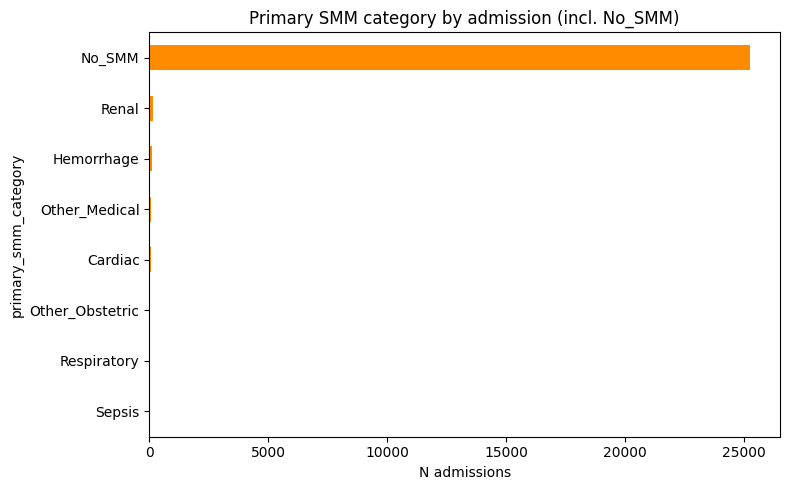

In [144]:
cat_ref = df_category_reference.copy()

print("Distribution of the primary SMM category (includes 'No_SMM'):")
print(cat_ref["primary_smm_category"].value_counts())

plt.figure(figsize=(8,5))
cat_ref["primary_smm_category"].value_counts().plot(kind="barh", color="darkorange")
plt.title("Primary SMM category by admission (incl. No_SMM)")
plt.xlabel("N admissions")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Fig_SMM_Primary_Category_Distribution.pdf"), format="pdf", bbox_inches="tight")
plt.savefig(os.path.join(FIG_DIR, "Fig_SMM_Primary_Category_Distribution.png"), format="png", dpi=300, bbox_inches="tight")
plt.show()

Number of distinct categories affected per SMM-positive admission:
1    364
2     64
3     27
4     17
5      3
Name: count, dtype: int64

% of SMM cases with >1 simultaneous category: 23.4%


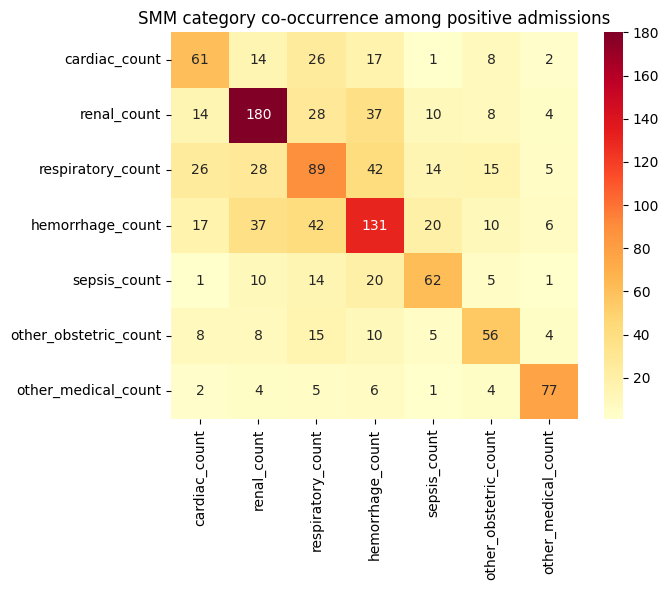

In [145]:
category_count_cols = ["cardiac_count", "renal_count", "respiratory_count", "hemorrhage_count",
                       "sepsis_count", "other_obstetric_count", "other_medical_count"]
category_count_cols = [c for c in category_count_cols if c in cat_ref.columns]

# Co-occurrence: among SMM-positive admissions, how many combine more than one category
smm_positive = cat_ref[cat_ref["outcome_smm"] == 1].copy()
category_flags = (smm_positive[category_count_cols] > 0).astype(int)

n_categories_per_case = category_flags.sum(axis=1)
print("Number of distinct categories affected per SMM-positive admission:")
print(n_categories_per_case.value_counts().sort_index())
print(f"\n% of SMM cases with >1 simultaneous category: "
      f"{(n_categories_per_case > 1).mean()*100:.1f}%")

cooccurrence = category_flags.T.dot(category_flags)

plt.figure(figsize=(7,6))
sns.heatmap(cooccurrence, annot=True, fmt="d", cmap="YlOrRd")
plt.title("SMM category co-occurrence among positive admissions")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Fig_SMM_Category_Cooccurrence.pdf"), format="pdf", bbox_inches="tight")
plt.savefig(os.path.join(FIG_DIR, "Fig_SMM_Category_Cooccurrence.png"), format="png", dpi=300, bbox_inches="tight")
plt.show()

Recalibration of the out-of-fold stacking probabilities -- SMM -- N = 25736, events = 475, prevalence = 0.01846
Calibration maps fitted inside 5-fold CV (repeated 20x); mean over repetitions.



,Brier,Brier skill,mean pred / prevalence,ECE (10 quantile bins),slope,intercept,AUC,AP
Raw (class-weighted),0.0925,-4.1040,13.5147,0.2310,1.0422,-4.0304,0.9019,0.3960
Platt,0.0134,0.2604,1.0016,0.0009,1.0001,-0.0007,0.9011,0.3944
Isotonic,0.0135,0.2556,0.9992,0.0011,0.9664,-0.0841,0.8953,0.3696



SD across repetitions (variability of the calibration folds only):


,Brier,Brier skill,mean pred / prevalence,ECE (10 quantile bins),slope,intercept,AUC,AP
Raw (class-weighted),0.0,-0.0000,0.0000,0.0000,0.0000,-0.0000,0.0000,0.0000
Platt,0.0,0.0003,0.0003,0.0002,0.0004,0.0010,0.0009,0.0013
Isotonic,0.0,0.0020,0.0027,0.0003,0.0063,0.0176,0.0015,0.0030


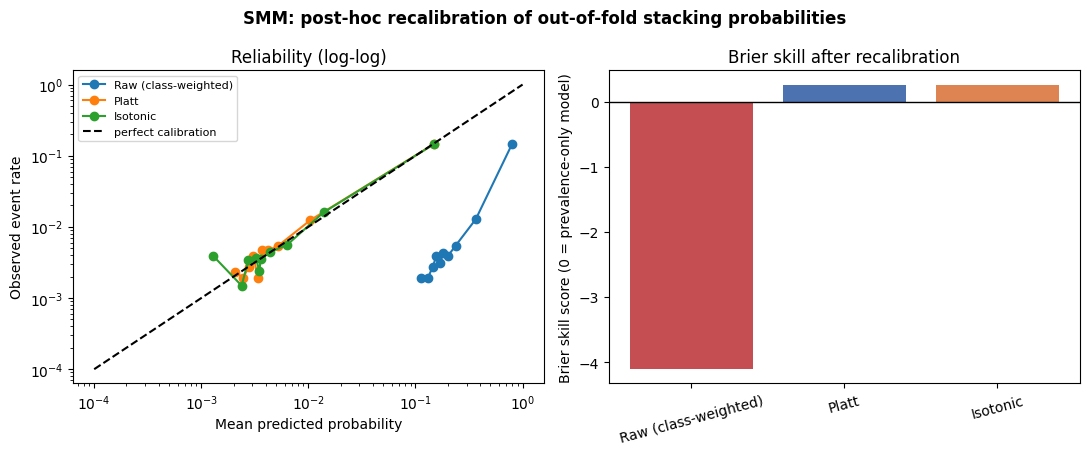

In [146]:
N_REPEATS_CAL = 20      # repetitions of the calibration cross-validation (different fold assignments)
N_SPLITS_CAL = 5

def _logit(p, eps=1e-6):
    p = np.clip(np.asarray(p, dtype=float), eps, 1 - eps)
    return np.log(p / (1 - p))

def _ece_quantile(y_true, y_prob, n_bins=10):
    """Expected calibration error with equal-frequency bins."""
    y_true = np.asarray(y_true); y_prob = np.asarray(y_prob)
    bins = np.array_split(np.argsort(y_prob, kind="mergesort"), n_bins)
    return float(sum(len(b) / len(y_true) * abs(y_true[b].mean() - y_prob[b].mean()) for b in bins))

def _slope_intercept(y_true, y_prob):
    """Calibration slope and intercept: logistic regression of the outcome on logit(p). Ideal: slope 1, intercept 0."""
    lr = LogisticRegression(C=1e6, max_iter=2000).fit(_logit(y_prob).reshape(-1, 1), y_true)
    return float(lr.coef_[0, 0]), float(lr.intercept_[0])

def _fit_predict_calibrator(method, p_tr, y_tr, p_te):
    if method == "Platt":
        cal = LogisticRegression(C=1e6, max_iter=2000).fit(_logit(p_tr).reshape(-1, 1), y_tr)
        return cal.predict_proba(_logit(p_te).reshape(-1, 1))[:, 1]
    cal = IsotonicRegression(y_min=0.0, y_max=1.0, out_of_bounds="clip").fit(p_tr, y_tr)
    return cal.predict(p_te)

def _metrics(y_true, p):
    prev = y_true.mean()
    brier = brier_score_loss(y_true, p); brier_ref = brier_score_loss(y_true, np.full(len(y_true), prev))
    slope, intercept = _slope_intercept(y_true, p)
    return {"Brier": brier, "Brier skill": 1 - brier / brier_ref, "mean pred / prevalence": p.mean() / prev,
            "ECE (10 quantile bins)": _ece_quantile(y_true, p), "slope": slope, "intercept": intercept,
            "AUC": roc_auc_score(y_true, p), "AP": average_precision_score(y_true, p)}

y_arr = np.asarray(y).astype(int); p_raw = np.asarray(y_oof, dtype=float)
rows = {"Raw (class-weighted)": [_metrics(y_arr, p_raw)]}
examples = {}
for method in ["Platt", "Isotonic"]:
    rows[method] = []
    for r in range(N_REPEATS_CAL):
        skf_cal = StratifiedKFold(n_splits=N_SPLITS_CAL, shuffle=True, random_state=100 + r)
        p_cal = np.zeros(len(y_arr))
        for tr, te in skf_cal.split(p_raw.reshape(-1, 1), y_arr):
            p_cal[te] = _fit_predict_calibrator(method, p_raw[tr], y_arr[tr], p_raw[te])
        rows[method].append(_metrics(y_arr, p_cal))
        if r == 0:
            examples[method] = p_cal.copy()

summary = pd.DataFrame({k: pd.DataFrame(v).mean() for k, v in rows.items()}).T
summary_sd = pd.DataFrame({k: pd.DataFrame(v).std(ddof=1) if len(v) > 1 else pd.DataFrame(v).mean() * 0 for k, v in rows.items()}).T
print(f"Recalibration of the out-of-fold stacking probabilities -- {LABEL} -- N = {len(y_arr)}, events = {int(y_arr.sum())}, "
      f"prevalence = {y_arr.mean():.5f}")
print(f"Calibration maps fitted inside {N_SPLITS_CAL}-fold CV (repeated {N_REPEATS_CAL}x); mean over repetitions.\n")
display(summary.round(4))
print("\nSD across repetitions (variability of the calibration folds only):")
display(summary_sd.round(4))
summary.round(5).to_csv(os.path.join(DATA_DIR, f"Table_Recalibration_{LABEL}.csv"))

# Rank-based metrics: each calibration map is monotonic, but maps differ between folds, so pooled AUC/AP can change slightly;
# isotonic regression also creates ties and can lose resolution.
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
curves = {"Raw (class-weighted)": p_raw, "Platt": examples["Platt"], "Isotonic": examples["Isotonic"]}
for name, pp in curves.items():
    fp, mp = calibration_curve(y_arr, pp, n_bins=10, strategy="quantile")
    ok = (fp > 0) & (mp > 0)
    ax[0].plot(mp[ok], fp[ok], "o-", label=name)
lo = 1e-4
ax[0].plot([lo, 1], [lo, 1], "k--", label="perfect calibration")
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("Mean predicted probability"); ax[0].set_ylabel("Observed event rate")
ax[0].set_title("Reliability (log-log)"); ax[0].legend(fontsize=8)
ax[1].bar(summary.index, summary["Brier skill"], color=["#C44E52", "#4C72B0", "#DD8452"])
ax[1].axhline(0, color="k", linewidth=1)
ax[1].set_ylabel("Brier skill score (0 = prevalence-only model)"); ax[1].set_title("Brier skill after recalibration")
ax[1].tick_params(axis="x", rotation=15)
fig.suptitle(f"{LABEL}: post-hoc recalibration of out-of-fold stacking probabilities", weight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f"Fig_Recalibration_{LABEL}.pdf"), format="pdf", bbox_inches="tight")
plt.savefig(os.path.join(FIG_DIR, f"Fig_Recalibration_{LABEL}.png"), format="png", dpi=300, bbox_inches="tight")
plt.show()

**Secondary multiclass model (future work, not run here).** Conditioned on `outcome_smm = 1`,
a multiclass classifier could be trained to predict `primary_smm_category` from the same clinical
variables in `X` (again excluding the `*_count` columns -- these DO determine the label by
construction and cannot be used as predictors of themselves). This would answer a different clinical
question ("what type of severe complication is most likely, given that SMM occurred?") and is outside the
scope of this notebook's main binary model.

```python
# Illustrative skeleton -- NOT executed here (needs a real, populated dataset).
# smm_only = df_model_multiclass[df_model_multiclass["outcome"] == 1].copy()
# X_multi = smm_only.drop(columns=["outcome", "primary_smm_category"])
# y_multi = smm_only["primary_smm_category"]
#
# X_multi_train, X_multi_test, y_multi_train, y_multi_test = train_test_split(
#     X_multi, y_multi, test_size=0.2, random_state=42, stratify=y_multi
# )
#
# model_multi = RandomForestClassifier(class_weight="balanced_subsample", random_state=42)
# model_multi.fit(X_multi_train, y_multi_train)
# print(classification_report(y_multi_test, model_multi.predict(X_multi_test)))
```


### **16. Modelo A vs. Modelo B -- final summary**

| Metric / aspect | Modelo A (mortality) | Modelo B (SMM, this notebook) |
|---|---|---|
| N positives (25,736 admissions) | 41 | 475 (252 of 8,857 delivery hospitalizations) |
| Prevalence | 0.159% | 1.846% (2.845% in deliveries) |
| Positive cases in test (80/20) | 8 | 95 |
| Main tuning metric | `average_precision` | `average_precision` (same) |
| Predictors | 89 (includes 26 `gdg_m*` diagnostic groups; see sensitivity run in Section 12.8 of Modelo A) | 65 (no `gdg_m*`, no outcome-derived columns, no delivery flag) |
| Stacking, hold-out AUC / AP | 0.866 / 0.129 | 0.913 / 0.384 |
| Primary evidence | 5-fold CV (stacking AUC 0.871 +/- 0.050, AP 0.162 +/- 0.089) | 5-fold CV in Section 12.7 + hold-out |
| Methodological rating | Exploratory / hypothesis-generating | More robust, but ICD-based labels, single center, no external validation |
| Model-specific variables | None | `is_delivery_hospitalization` is **not** a predictor; it only defines the evaluation subset of Section 12.6. The 7 category counts are descriptive/multiclass only (excluded from X to avoid leakage) |

Both models complement each other: Modelo A informs on the most severe and rare event (death), Modelo B
on a more frequent event that, per Callaghan et al. (2012), is ~100 times more common -- enabling a
predictive model with greater statistical power to support early-surveillance clinical decisions.

### **17. Limitations and Open Design Questions for Emmanuel**

This section documents, with full transparency, the assumptions adopted while building this notebook
without access to a real MIMIC-IV instance, so they can be validated or corrected before running the
real pipeline:

1. **Run both SQL scripts first.** This notebook assumes `sql/02_cohort_mortality/maternal_cohort_expanded_en.sql`
   and `sql/03_cohort_smm/smm_cohort_en.sql` have already been run against the real database (creating
   `mimiciv.pregnancy_diagnoses_expanded`, `mimiciv.smm_code_patterns`, `mimiciv.hadm_with_smm`,
   `mimiciv.hadm_delivery_hospitalization`) and that `mimiciv.cohort_smm_dataset` (Section 2.8) has been
   assembled from them following the pattern described -- none of these objects exist yet; **nothing in
   this notebook has been run**.
2. **The denominator decision (Section 2.5) is the most important to validate.** We chose to train on
   the full expanded cohort (more cases, unofficial denominator) (`is_delivery_hospitalization` is kept only as a reference flag for the Section 12.6 subset check, **not** as a predictor, since it is derived from discharge-coded diagnoses), instead of restricting the model to deliveries only (the official CDC
   denominator, likely fewer absolute cases but comparable 1:1 with the literature). Confirm with
   Emmanuel whether this is the right decision for the thesis, or whether the main model should be
   inverted (train on deliveries only, report the expanded cohort as sensitivity).
3. **Coverage of the 20 indicators against MIMIC-IV's real catalogue.** The code patterns
   (`LIKE pattern || '%'`) were taken directly from the Nebraska DHHS / HRSA FAD 2023 report; it has
   not been verified how many of those prefixes actually appear in `mimiciv.d_icd_diagnoses` /
   `mimiciv.d_icd_procedures` in this MIMIC-IV version. Before interpreting the results, run a
   coverage `SELECT` (how many `code_pattern`s have 0 matches) to catch outdated or mistyped prefixes.
4. **`mimiciv.cohort_smm_dataset` is a proposed assembly, not a tested script.** The SQL in
   Section 2.8 (especially the per-category count pivot via `FILTER (WHERE ...)` and `MODE() WITHIN
   GROUP`) has not been run; review its syntax and performance (the nested `FILTER`s over
   `hadm_with_smm` may need indexes on `(subject_id, hadm_id, indicator_group)` to be efficient at
   this scale).
5. **Reuse of the `gdg_m*` diagnostic groups.** This notebook assumes that the same 30 diagnostic
   groups (28 expert + 2 residual) defined for Modelo A are also valid for Modelo B. Since the outcome
   changes (SMM instead of death), **the clinical panel should review whether those groups are still
   the most informative grouping**, or whether a SMM-specific reclassification is warranted.
6. **`primary_smm_category` via `MODE()` is a simplification.** In ties between categories (e.g. an
   admission with 1 Cardiac indicator and 1 Hemorrhage indicator) the tiebreak is arbitrary. If Section 15
   (secondary multiclass model) is pursued, define a clinical severity criterion to break ties, not just
   alphabetical/`MODE()`.
7. **Outlier removal (Section 5) and the `GridSearchCV` metric choice** (`average_precision`,
   same as Modelo A) must be revalidated once real data is available -- confirm whether the IQR factor
   or the tuning metric should be adjusted given the larger N of positive cases.
8. **SMOTE** remains available but not applied by default (Section 11); with a larger positive N than
   Modelo A, it is more defensible as a sensitivity analysis -- confirm with Emmanuel whether it should be
   incorporated into the main pipeline.
9. **Possible overlap between Modelo A and Modelo B.** Both start from related obstetric universes
   (original vs. expanded cohort); confirm that the same `hadm_id` can legitimately be positive in
   both models (a patient can die AND have had SMM in the same admission) without that implying a
   cohort-construction error.

> All indicator/category figures cited in this notebook (20 CDC/HRSA FAD-2023 indicators, 7
> categories, 58-88 SMM per 10,000 deliveries, ~100x more frequent than death per Callaghan et al. 2012)
> come from research already validated by Emmanuel and documented in
> `sql/03_cohort_smm/smm_cohort_en.sql`; the rest of the pipeline (cleaning, imputation, models,
> imbalance handling) is a methodological adaptation of `maternal_mortality_models.ipynb` that **has not
> been run** against the real database -- all the code should be treated as a syntactically valid draft,
> pending end-to-end validation.


> **Update 2026-10-09.** Two further decisions are now in force: (i) `gdg_m01`-`gdg_m28` are excluded from the predictors because they are built from the same coded diagnoses that define the outcome (information leakage; `INCLUDE_GDG_FEATURES` flag in Section 10 for an explicit sensitivity run), and (ii) outliers are winsorized instead of deleted (Section 5), after the first run showed that row deletion removed 39% of the SMM cases.
